## 1、定位项目和数据文件夹

In [1]:
from pathlib import Path

current_folder = Path.cwd().resolve()

project_folder = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (folder / ".git").exists()
    ),
    None
)

if project_folder is None:
    raise FileNotFoundError("未找到项目仓库，请在克隆的项目中运行 Notebook。")

data_folder = project_folder / "data" / "raw"

if not data_folder.is_dir():
    raise FileNotFoundError(f"未找到数据文件夹：{data_folder}")

print("项目位置：", project_folder)
print("数据位置：", data_folder)

项目位置： D:\course\data analysis\group project\ecommerce-customer-analysis
数据位置： D:\course\data analysis\group project\ecommerce-customer-analysis\data\raw


## 2、检查六个文件的行数、字段和前3行

In [2]:
import pyarrow.parquet as pq
from IPython.display import display

file_names = [
    "add_to_cart.parquet",
    "page_visit.parquet",
    "product_buy.parquet",
    "product_properties.parquet",
    "remove_from_cart.parquet",
    "search_query.parquet",
]

for file_name in file_names:
    file_path = data_folder / file_name
    print(f"\n文件：{file_name}")

    if not file_path.exists():
        print("未找到，请检查是否已放入 data/raw。")
        continue

    parquet_file = pq.ParquetFile(file_path)

    print(f"总行数：{parquet_file.metadata.num_rows:,}")
    print("字段与类型：")
    print(parquet_file.schema_arrow)

    first_batch = next(
        parquet_file.iter_batches(batch_size=3),
        None
    )

    if first_batch is not None:
        display(first_batch.to_pandas())


文件：add_to_cart.parquet
总行数：7,541,117
字段与类型：
client_id: int64
timestamp: string
sku: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 411


,client_id,timestamp,sku
0,18080713,2022-08-06 15:17:25,219064
1,8081030,2022-09-19 17:45:25,1375125
2,4480154,2022-12-06 06:35:15,1291128



文件：page_visit.parquet
总行数：199,451,980
字段与类型：
client_id: int64
timestamp: string
url: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 411


,client_id,timestamp,url
0,19155437,2022-07-13 10:37:45,2310881
1,19155437,2022-08-11 18:13:20,952215
2,15175374,2022-07-25 09:47:10,5409374



文件：product_buy.parquet
总行数：2,318,502
字段与类型：
client_id: int64
timestamp: string
sku: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 411


,client_id,timestamp,sku
0,14534769,2022-07-07 20:03:10,91300
1,14534769,2022-12-02 12:32:05,660194
2,4480154,2022-12-06 06:38:20,1291128


... (2 outputs left out)


文件：remove_from_cart.parquet
总行数：2,688,894
字段与类型：
client_id: int64
timestamp: string
sku: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 411


,client_id,timestamp,sku
0,4480154,2022-12-06 06:35:30,551275
1,10551361,2022-09-22 06:26:55,728970
2,10551361,2022-10-15 20:20:05,655683



文件：search_query.parquet
总行数：13,223,769
字段与类型：
client_id: int64
timestamp: string
query: string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 418


,client_id,timestamp,query
0,14554694,2022-10-15 20:06:40,[240 170 240 207 251 138 16 169 162 254 170 1...
1,14554694,2022-10-15 20:07:00,[174 61 58 154 154 57 102 102 195 167 68 ...
2,2406455,2022-07-12 06:15:30,[250 172 48 48 7 122 145 116 60 122 204 2...


## 3、分批检查五张行为表的时间范围与时间质量。
分批扫描五张行为表的时间字段，检查：
- 时间缺失数量
- 不符合指定格式的时间数量
- 最早与最晚记录时间

In [3]:
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

event_files = [
    "add_to_cart.parquet",
    "page_visit.parquet",
    "product_buy.parquet",
    "remove_from_cart.parquet",
    "search_query.parquet",
]

time_summary = []

for file_name in event_files:
    print(f"正在检查：{file_name}", flush=True)

    parquet_file = pq.ParquetFile(data_folder / file_name)

    total_rows = 0
    missing_count = 0
    invalid_count = 0
    earliest_time = None
    latest_time = None

    for batch in parquet_file.iter_batches(
        batch_size=200_000,
        columns=["timestamp"]
    ):
        raw_time = batch.column(0).to_pandas()

        # 按样本中的格式转换；无法解析的时间记为 NaT
        parsed_time = pd.to_datetime(
            raw_time,
            format="%Y-%m-%d %H:%M:%S",
            errors="coerce"
        )

        total_rows += len(raw_time)
        missing_count += int(raw_time.isna().sum())
        invalid_count += int(
            (raw_time.notna() & parsed_time.isna()).sum()
        )

        batch_min = parsed_time.min()
        batch_max = parsed_time.max()

        if pd.notna(batch_min):
            if earliest_time is None or batch_min < earliest_time:
                earliest_time = batch_min

        if pd.notna(batch_max):
            if latest_time is None or batch_max > latest_time:
                latest_time = batch_max

    time_summary.append({
        "文件": file_name,
        "行数": total_rows,
        "时间缺失数": missing_count,
        "时间格式异常数": invalid_count,
        "最早时间": earliest_time,
        "最晚时间": latest_time,
    })

    print(f"完成：{file_name}", flush=True)

time_summary = pd.DataFrame(time_summary)
display(time_summary)

正在检查：add_to_cart.parquet
完成：add_to_cart.parquet
正在检查：page_visit.parquet
完成：page_visit.parquet
正在检查：product_buy.parquet
完成：product_buy.parquet
正在检查：remove_from_cart.parquet
完成：remove_from_cart.parquet
正在检查：search_query.parquet
完成：search_query.parquet


,文件,行数,时间缺失数,时间格式异常数,最早时间,最晚时间
0,add_to_cart.parquet,7541117,0,0,2022-06-23 00:10:20,2022-12-08 00:09:55
1,page_visit.parquet,199451980,0,0,2022-06-23 00:10:00,2022-12-08 00:09:59
2,product_buy.parquet,2318502,0,0,2022-06-23 00:12:15,2022-12-08 00:09:15
3,remove_from_cart.parquet,2688894,0,0,2022-06-23 00:12:25,2022-12-08 00:09:40
4,search_query.parquet,13223769,0,0,2022-06-23 00:10:00,2022-12-08 00:09:55


### 检查结果与初步判断

五张行为表的时间缺失数及指定格式解析异常数均为0。
记录覆盖2022年6月23日至2022年12月8日凌晨。

12月8日仅覆盖约前10分钟，属于不完整日期。
后续按日比较时需排除该日，或单独标注。
6月23日是否完整、期间是否存在记录中断，还需结合每日分布检查。

以上结果仅说明时间字段可以按指定格式解析，
不代表数据不存在重复、采集遗漏或其他质量问题。

目前没有确认时间字段的时区，因此小时分布暂按原始记录时间解释。

## 4. 商品属性表质量检查

读取商品编号、类目编号和价格档位，检查缺失情况与商品编号唯一性。

购买、加购等行为需要通过 `sku` 关联商品属性。
如果商品属性表中一个 `sku` 对应多行，直接合并可能导致行为记录被重复扩增。

本步骤只检查，不删除重复记录，不填补缺失值。

In [4]:
# 只读取当前检查需要的字段，暂不加载编码商品名
product_properties = pq.read_table(
    data_folder / "product_properties.parquet",
    columns=["sku", "category", "price"]
).to_pandas()

# 各字段缺失数量及比例
product_quality = pd.DataFrame({
    "数据类型": product_properties.dtypes.astype(str),
    "缺失数量": product_properties.isna().sum(),
    "缺失比例(%)": (
        product_properties.isna().mean() * 100
    ).round(4),
})

print("商品属性字段质量：")
display(product_quality)

# 检查商品编号是否唯一
missing_sku_count = int(product_properties["sku"].isna().sum())
unique_sku_count = product_properties["sku"].nunique()

# 重复编号对应的全部行，包括每组第一次出现的记录
duplicate_sku_mask = product_properties["sku"].duplicated(
    keep=False
)

print(f"商品属性总行数：{len(product_properties):,}")
print(f"非空唯一商品编号数：{unique_sku_count:,}")
print(f"商品编号缺失数：{missing_sku_count:,}")
print(f"重复商品编号涉及行数：{duplicate_sku_mask.sum():,}")

print(
    "商品编号是否可作为唯一关联键：",
    missing_sku_count == 0
    and product_properties["sku"].is_unique
)

print(f"不同类目编号数：{product_properties['category'].nunique():,}")
print(f"不同价格档位数：{product_properties['price'].nunique():,}")

# 如有重复，先展示样本，后续判断是否存在属性冲突
if duplicate_sku_mask.any():
    print("\n重复商品编号样本：")
    display(
        product_properties.loc[duplicate_sku_mask]
        .sort_values("sku")
        .head(10)
    )

商品属性字段质量：


,数据类型,缺失数量,缺失比例(%)
sku,int64,0,0.0
category,int64,0,0.0
price,int64,0,0.0


商品属性总行数：1,534,050
非空唯一商品编号数：1,534,050
商品编号缺失数：0
重复商品编号涉及行数：0
商品编号是否可作为唯一关联键： True
不同类目编号数：6,912
不同价格档位数：100


### 商品属性质量检查结果

商品属性表共1,534,050行，包含1,534,050个唯一商品编号。
`sku`、`category`、`price` 均无缺失，商品编号无重复。

因此，商品属性表可以通过 `sku` 与行为记录进行多对一关联，
不会因商品表存在重复键而扩增行为行数。
行为商品编号的实际匹配率仍需后续检查。

数据包含6,912个类目编号和100个价格档位。
类目编号为匿名分类标识，价格档位不代表实际交易金额。

## 5. 行为数据的每日覆盖检查

分批统计五类行为每天的记录数，并补齐日期索引，
检查是否存在无记录日期以及边界日期是否覆盖不足。

统计单位为行为记录数，不是用户人数或订单数。
日期无记录不一定代表系统故障，也可能与业务活动或数据采集有关。

本步骤不删除记录，结果用于确定后续分析和预测窗口。

In [5]:
event_names = {
    "add_to_cart.parquet": "加购",
    "page_visit.parquet": "页面访问",
    "product_buy.parquet": "购买",
    "remove_from_cart.parquet": "移出购物车",
    "search_query.parquet": "搜索",
}

daily_series = {}

for file_name, event_name in event_names.items():
    print(f"正在统计：{event_name}", flush=True)

    parquet_file = pq.ParquetFile(data_folder / file_name)
    date_totals = pd.Series(dtype="int64")

    for batch in parquet_file.iter_batches(
        batch_size=200_000,
        columns=["timestamp"]
    ):
        raw_time = batch.column(0).to_pandas()

        parsed_time = pd.to_datetime(
            raw_time,
            format="%Y-%m-%d %H:%M:%S",
            errors="coerce"
        )

        # 本阶段遇到异常就停止，避免静默漏掉记录
        if parsed_time.isna().any():
            raise ValueError(f"{file_name} 存在缺失或无法解析的时间。")

        # 将时间归到当天零点，再累计每天的事件数
        batch_counts = parsed_time.dt.normalize().value_counts()
        date_totals = date_totals.add(batch_counts, fill_value=0)

    daily_series[event_name] = date_totals.astype("int64").sort_index()
    print(f"完成：{event_name}", flush=True)

# 合并五类行为，并补齐整个时间范围内的日期
daily_counts = pd.DataFrame(daily_series).sort_index()

all_dates = pd.date_range(
    start=daily_counts.index.min(),
    end=daily_counts.index.max(),
    freq="D"
)

daily_counts = (
    daily_counts.reindex(all_dates)
    .fillna(0)
    .astype("int64")
)
daily_counts.index.name = "日期"

# 检查每日累计数是否与原始文件行数一致
for file_name, event_name in event_names.items():
    expected_rows = pq.ParquetFile(
        data_folder / file_name
    ).metadata.num_rows

    assert int(daily_counts[event_name].sum()) == expected_rows, (
        f"{event_name}：每日累计数与文件行数不一致"
    )

print("\n每日累计数与五个原始文件行数全部一致。")

print("\n最前5天：")
display(daily_counts.head())

print("\n最后5天：")
display(daily_counts.tail())

# 各行为无记录日期数量
coverage_summary = pd.DataFrame({
    "行为": daily_counts.columns,
    "覆盖日期数": [
        int((daily_counts[column] > 0).sum())
        for column in daily_counts.columns
    ],
    "无记录日期数": [
        int((daily_counts[column] == 0).sum())
        for column in daily_counts.columns
    ],
})

print("\n每日覆盖汇总：")
display(coverage_summary)

# 单独展示缺少某类行为的日期，最多显示20天
zero_dates = daily_counts.eq(0).any(axis=1)

print(f"\n至少一类行为无记录的日期数：{zero_dates.sum()}")
if zero_dates.any():
    display(daily_counts.loc[zero_dates].head(20))

正在统计：加购
完成：加购
正在统计：页面访问
完成：页面访问
正在统计：购买
完成：购买
正在统计：移出购物车
完成：移出购物车
正在统计：搜索
完成：搜索

每日累计数与五个原始文件行数全部一致。

最前5天：


,加购,页面访问,购买,移出购物车,搜索
日期,,,,,
2022-06-23,25214,773980,9036,7367,49346
2022-06-24,19264,625697,6977,5831,39206
2022-06-25,17583,582734,6012,5081,37171
2022-06-26,24316,760696,8565,7453,53539
2022-06-27,27703,821911,11062,8145,54698



最后5天：


,加购,页面访问,购买,移出购物车,搜索
日期,,,,,
2022-12-04,93388,1973489,23408,38774,144846
2022-12-05,84172,1848938,22979,35113,122268
2022-12-06,82540,1809997,21915,34332,120552
2022-12-07,81179,1750025,21906,34471,117550
2022-12-08,188,3124,24,97,285



每日覆盖汇总：


,行为,覆盖日期数,无记录日期数
0,加购,169,0
1,页面访问,169,0
2,购买,169,0
3,移出购物车,169,0
4,搜索,169,0



至少一类行为无记录的日期数：0


### 每日覆盖检查结果

五类行为均覆盖169个日期，各类行为均未出现整日零记录。
按日汇总后的记录总数与原始文件行数一致。

数据首日为2022年6月23日，最早记录约为00:10；
末日为2022年12月8日，仅覆盖凌晨约10分钟。

为减少边界日期覆盖不足造成的影响，日度展示暂使用
2022年6月24日至2022年12月7日，共167天。

该检查排除了整日零记录的情况，但不能证明每天各时段均采集完整。

## 6. 五类行为的日度趋势

分别展示五类行为的每日记录数和7日移动平均线。

- 细线：每天的实际行为记录数。
- 粗线：当日及此前6天的平均记录数，用于辅助观察趋势。
- 各子图使用独立纵轴，避免页面访问量掩盖其他行为的变化。
- 统计单位为行为记录数，不是用户数或订单数。

本图属于描述性分析，不用于证明变化的原因。

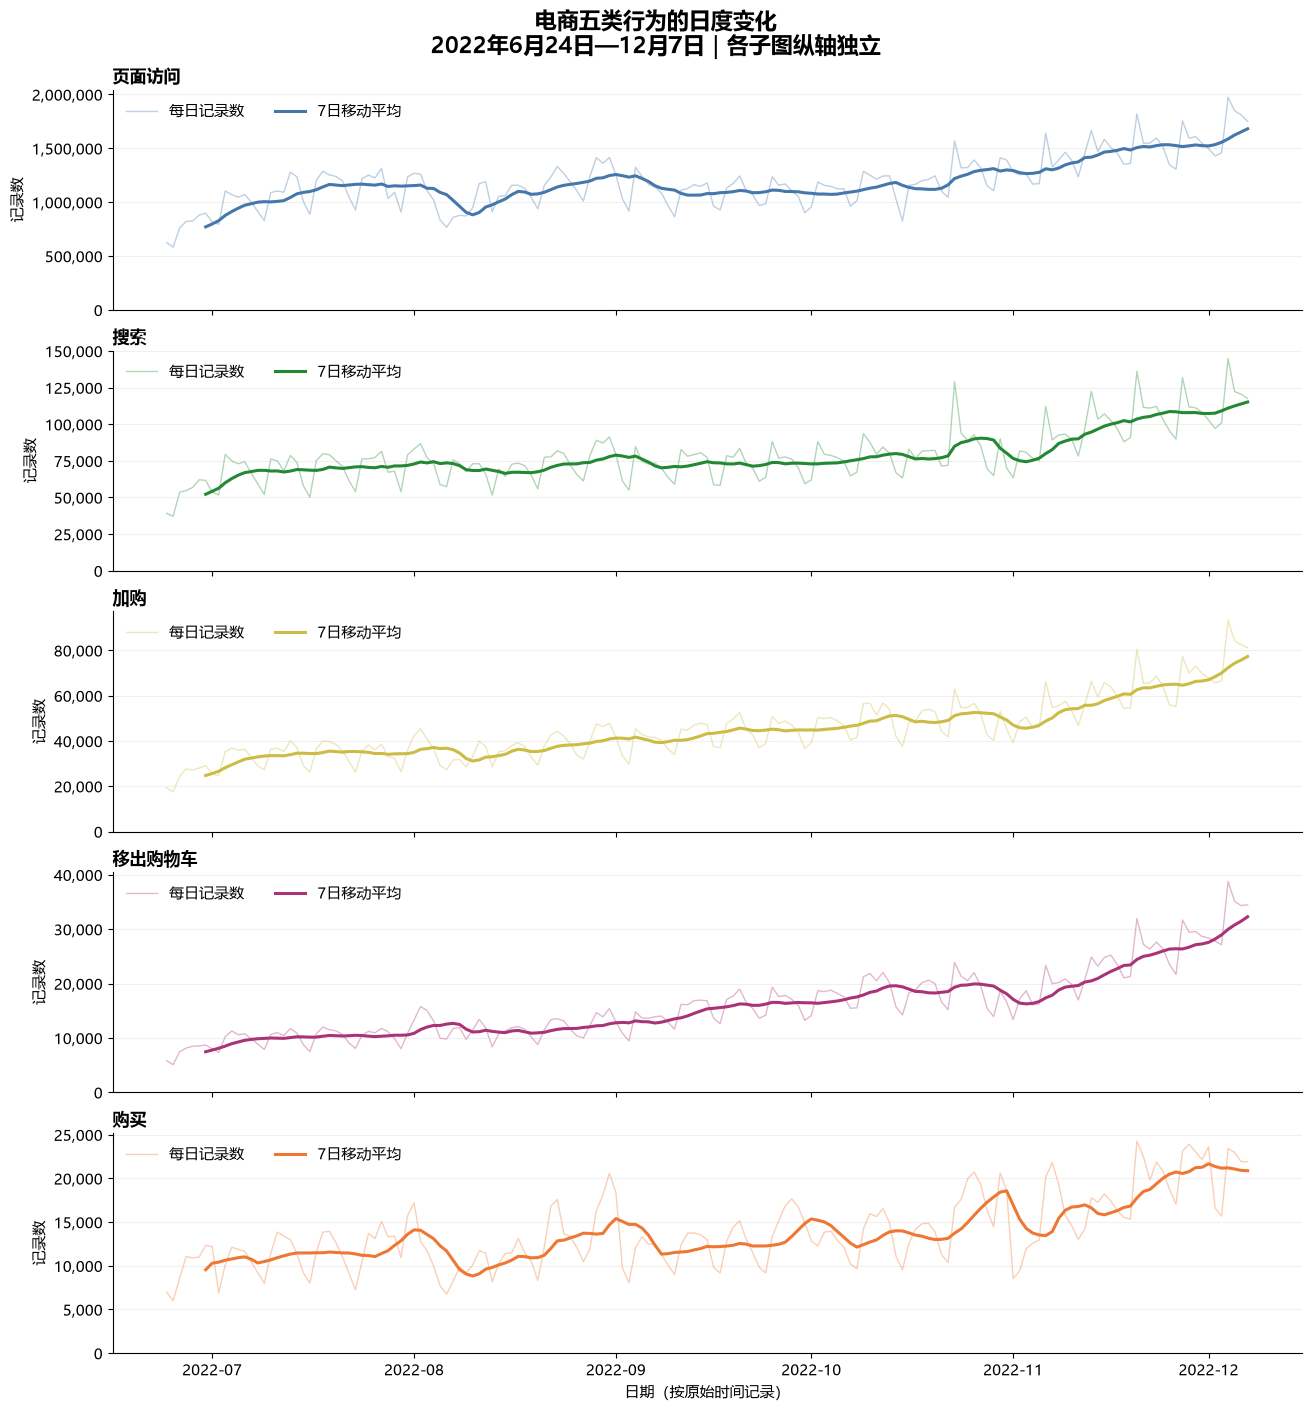

分析日期数：167
图表保存位置： D:\course\data analysis\group project\ecommerce-customer-analysis\figures


In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter

# 自动选择已安装的中文字体
available_fonts = {
    font.name for font in font_manager.fontManager.ttflist
}
chinese_fonts = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "SimSun",
]

selected_font = next(
    (name for name in chinese_fonts if name in available_fonts),
    None
)

if selected_font:
    plt.rcParams["font.sans-serif"] = [selected_font]
else:
    print("未检测到常用中文字体；如文字显示为方框，请告诉我。")

plt.rcParams["axes.unicode_minus"] = False

# 排除首尾边界日期；保留原始 daily_counts 不变
daily_analysis = daily_counts.loc[
    "2022-06-24":"2022-12-07"
].copy()

assert len(daily_analysis) == 167, "分析日期数量与预期不一致。"

figure_folder = project_folder / "figures"
figure_folder.mkdir(parents=True, exist_ok=True)

event_colors = {
    "页面访问": "#4477AA",
    "搜索": "#228833",
    "加购": "#CCBB44",
    "移出购物车": "#AA3377",
    "购买": "#EE7733",
}

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(
        nrows=5,
        ncols=1,
        figsize=(13, 14),
        sharex=True,
        layout="constrained"
    )

    for ax, (event_name, color) in zip(
        axes, event_colors.items()
    ):
        daily_values = daily_analysis[event_name]

        # 仅使用当日和过去6天；前6天不显示移动平均
        moving_average = daily_values.rolling(
            window=7,
            min_periods=7
        ).mean()

        ax.plot(
            daily_values.index,
            daily_values.values,
            color=color,
            alpha=0.35,
            linewidth=1,
            label="每日记录数"
        )

        ax.plot(
            moving_average.index,
            moving_average.values,
            color=color,
            linewidth=2.2,
            label="7日移动平均"
        )

        ax.set_title(event_name, loc="left", fontweight="bold")
        ax.set_ylabel("记录数")
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda value, position: f"{value:,.0f}")
        )
        ax.grid(axis="y", alpha=0.18)
        ax.legend(loc="upper left", frameon=False, ncol=2)

    axes[-1].xaxis.set_major_locator(
        mdates.MonthLocator()
    )
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )
    axes[-1].set_xlabel("日期（按原始时间记录）")

    fig.suptitle(
        "电商五类行为的日度变化\n"
        "2022年6月24日—12月7日｜各子图纵轴独立",
        fontsize=16,
        fontweight="bold"
    )

    # PNG用于查看和PPT，PDF用于保留矢量图
    fig.savefig(
        figure_folder / "01_daily_behavior_trends.png",
        dpi=300,
        bbox_inches="tight"
    )
    fig.savefig(
        figure_folder / "01_daily_behavior_trends.pdf",
        bbox_inches="tight"
    )

    plt.show()

print(f"分析日期数：{len(daily_analysis)}")
print("图表保存位置：", figure_folder)

### 日度趋势的初步观察

五类行为在观察期末的记录量总体高于初期，但期间存在阶段性回落。
加购和移出购物车的上升较明显，购买行为同时呈现短期波动。

多类行为出现重复波动，后续将检查星期维度的分布。
由于子图采用独立纵轴，增长幅度需要通过数值计算比较。

以上结论描述的是行为记录量，不代表独立客户人数、销售额或转化率。
数据尚不足以确认变化由促销、节日或其他因素引起。

## 7. 期初与期末行为量比较

比较分析期最初28天与最后28天的日均行为记录数。
两个窗口均覆盖四个完整星期，减少星期构成不同带来的影响。

变化率 =（期末日均记录数 / 期初日均记录数 - 1）× 100%。

该比较仅用于描述历史变化，不用于证明因果关系，
也不用于选择预测模型或调整模型参数。

In [7]:
# 比较两个长度相同、互不重叠的28天窗口
window_days = 28

assert len(daily_analysis) >= 2 * window_days
assert daily_analysis.index.equals(
    pd.date_range(
        daily_analysis.index.min(),
        daily_analysis.index.max(),
        freq="D"
    )
), "日期必须连续且按天排列。"

early_period = daily_analysis.iloc[:window_days]
late_period = daily_analysis.iloc[-window_days:]

early_mean = early_period.mean()
late_mean = late_period.mean()

# 分母为0时不计算变化率，避免产生无穷值
change_rate = (
    late_mean.div(early_mean.where(early_mean.ne(0))) - 1
) * 100

trend_comparison = pd.DataFrame({
    "期初日均记录数": early_mean,
    "期末日均记录数": late_mean,
    "日均变化率(%)": change_rate,
})

trend_comparison.index.name = "行为"

print(
    f"期初窗口：{early_period.index.min():%Y-%m-%d}"
    f" 至 {early_period.index.max():%Y-%m-%d}"
)
print(
    f"期末窗口：{late_period.index.min():%Y-%m-%d}"
    f" 至 {late_period.index.max():%Y-%m-%d}"
)

display(trend_comparison.round(2))

期初窗口：2022-06-24 至 2022-07-21
期末窗口：2022-11-10 至 2022-12-07


,期初日均记录数,期末日均记录数,日均变化率(%)
行为,,,
加购,31710.07,66673.75,110.26
页面访问,996969.61,1550601.50,55.53
购买,10808.93,19395.86,79.44
移出购物车,9443.04,26843.82,184.27
搜索,64688.32,107309.04,65.89


### 期初与期末比较结果

比较2022年6月24日—7月21日与11月10日—12月7日两个28天窗口：

- 页面访问日均记录数增长55.53%。
- 搜索日均记录数增长65.89%。
- 加购日均记录数增长110.26%。
- 移出购物车日均记录数增长184.27%。
- 购买日均记录数增长79.44%。

购物车相关事件的相对增长较突出，购买事件增长也高于页面访问。
这些结果反映事件量的变化，不能直接解释为用户级转化率提升、
放弃购买增加或营销活动产生了因果效果。

两个窗口各覆盖四个完整星期，但仍可能受到用户构成、
业务规模、季节变化或采集方式等因素影响。

## 8. 星期维度的行为分布

按星期一至星期日，计算各类行为的日均记录数，
避免不同星期出现次数不一致造成总量比较偏差。

将每类行为的星期日均值除以其全期日均值，得到相对指数：
- 1表示与该行为全期日均水平一致。
- 大于1表示高于全期日均水平。
- 小于1表示低于全期日均水平。

星期按原始时间字段计算，时区尚未确认。
结果属于描述性比较，尚未控制长期增长和节假日等因素。

每个星期对应的观察天数：


,观察天数
星期一,24
星期二,24
星期三,24
星期四,23
星期五,24
星期六,24
星期日,24


不同星期的日均行为记录数：


,加购,页面访问,购买,移出购物车,搜索
星期一,48052.54,1256577.58,15891.58,17309.62,83385.42
星期二,48279.79,1261149.17,15238.67,17198.50,83270.17
星期三,48832.50,1261150.29,15119.12,17610.88,84234.54
星期四,45109.61,1198569.39,14059.17,16105.39,77990.52
星期五,38237.04,1053518.88,11737.62,13573.79,66981.54
星期六,36848.54,997657.75,10344.62,12866.67,64355.75
星期日,49674.33,1299437.17,14421.75,17732.46,91954.08


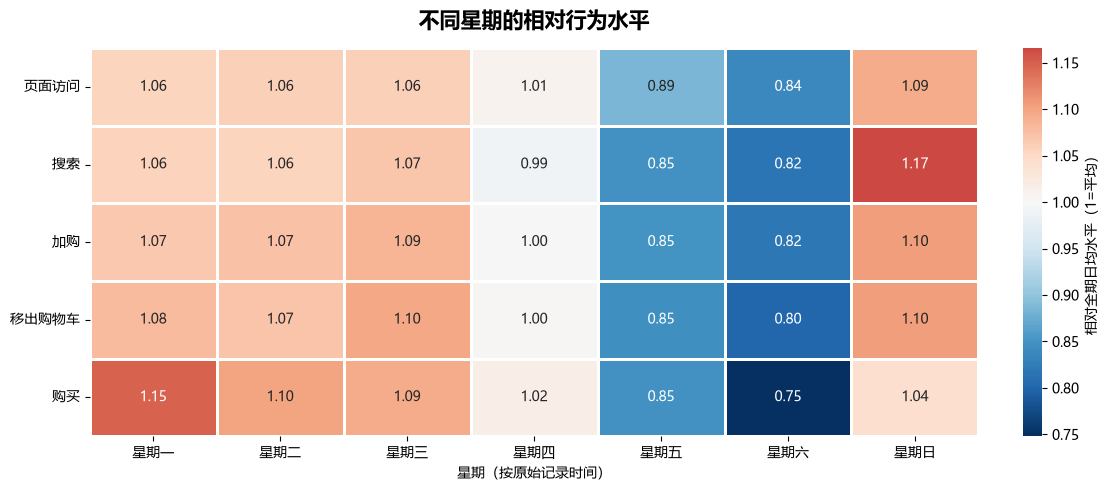

In [8]:
import seaborn as sns

weekday_names = [
    "星期一", "星期二", "星期三", "星期四",
    "星期五", "星期六", "星期日"
]

# 同一星期可能出现23或24次，因此比较日均值而不是总数
weekday_groups = daily_analysis.groupby(
    daily_analysis.index.dayofweek
)

weekday_mean = weekday_groups.mean().reindex(range(7))
weekday_days = weekday_groups.size().reindex(range(7))

weekday_mean.index = weekday_names
weekday_days.index = weekday_names

print("每个星期对应的观察天数：")
display(weekday_days.rename("观察天数").to_frame())

print("不同星期的日均行为记录数：")
display(weekday_mean.round(2))

# 按各类行为自身的全期日均值进行标准化
overall_mean = daily_analysis.mean()
weekday_index = weekday_mean.div(
    overall_mean.where(overall_mean.ne(0)),
    axis="columns"
)

# 与前一张图保持行为顺序一致
event_order = list(event_colors)
heatmap_data = weekday_index[event_order].T

fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=1,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "相对全期日均水平（1=平均）"},
    ax=ax
)

ax.set_title(
    "不同星期的相对行为水平",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("星期（按原始记录时间）")
ax.set_ylabel("")
ax.tick_params(axis="both", rotation=0)

fig.savefig(
    figure_folder / "02_weekday_behavior_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figure_folder / "02_weekday_behavior_heatmap.pdf",
    bbox_inches="tight"
)

plt.show()

### 星期维度分析结果

星期日的页面访问、搜索和加购日均记录数最高。
其中，搜索相对指数约为1.17，即高于全期日均水平约17%。

购买记录在星期一最多，日均约15,892条，
相对指数约为1.15；星期六最少，日均约10,345条，
相对指数约为0.75。

五类行为在星期五、星期六均低于各自的全期日均水平。
这说明不同星期的行为量存在差异，但尚未控制长期趋势、
节假日及用户构成等因素。

本分析没有追踪同一用户的跨日行为，
因此不能认定星期日的浏览直接带来了星期一的购买。
星期依据原始记录时间计算，时区解释仍有限制。

## 9. 商品行为记录与商品属性的关联覆盖检查

分批检查购买、加购及移出购物车记录中的用户编号和商品编号，
并统计非空商品编号在商品属性表中的匹配情况。

需要区分：
- 商品编号缺失：无法确定对应商品。
- 非空商品编号未匹配：行为中有商品编号，但商品属性表没有对应记录。

本步骤按行为记录数统计匹配比例，不代表唯一商品的覆盖比例。
未匹配记录暂时保留，不直接删除，以免改变行为总量或预测标签。
页面访问和搜索没有商品编号，不参与本项关联检查。

In [ ]:
# 第4格已确认：商品属性表的 sku 无缺失且唯一
assert product_properties["sku"].notna().all()
assert product_properties["sku"].is_unique

known_skus = pd.Index(product_properties["sku"])

sku_event_files = {
    "product_buy.parquet": "购买",
    "add_to_cart.parquet": "加购",
    "remove_from_cart.parquet": "移出购物车",
}

match_results = []

for file_name, event_name in sku_event_files.items():
    print(f"正在检查：{event_name}", flush=True)

    parquet_file = pq.ParquetFile(data_folder / file_name)

    total_rows = 0
    missing_client = 0
    missing_sku = 0
    matched_rows = 0
    unmatched_rows = 0

    for batch in parquet_file.iter_batches(
        batch_size=200_000,
        columns=["client_id", "sku"]
    ):
        batch_data = batch.to_pandas()

        total_rows += len(batch_data)
        missing_client += int(batch_data["client_id"].isna().sum())

        sku_is_missing = batch_data["sku"].isna()
        sku_is_matched = batch_data["sku"].isin(known_skus)

        missing_sku += int(sku_is_missing.sum())
        matched_rows += int(
            (~sku_is_missing & sku_is_matched).sum()
        )
        unmatched_rows += int(
            (~sku_is_missing & ~sku_is_matched).sum()
        )

    # 确认三类商品关联状态覆盖全部记录
    assert (
        missing_sku + matched_rows + unmatched_rows == total_rows
    )
    assert total_rows == parquet_file.metadata.num_rows

    nonmissing_sku_rows = total_rows - missing_sku

    match_results.append({
        "行为": event_name,
        "记录数": total_rows,
        "用户编号缺失数": missing_client,
        "商品编号缺失数": missing_sku,
        "成功匹配记录数": matched_rows,
        "非空商品未匹配记录数": unmatched_rows,
        "非空商品匹配率(%)": (
            matched_rows / nonmissing_sku_rows * 100
            if nonmissing_sku_rows > 0
            else float("nan")
        ),
    })

    print(f"完成：{event_name}", flush=True)

sku_match_summary = pd.DataFrame(match_results)
display(sku_match_summary.round(4))

正在检查：购买
完成：购买
正在检查：加购
完成：加购
正在检查：移出购物车
完成：移出购物车


,行为,记录数,用户编号缺失数,商品编号缺失数,成功匹配记录数,非空商品未匹配记录数,非空商品匹配率(%)
0,购买,2318502,0,0,2318502,0,100.0
1,加购,7541117,0,0,7541117,0,100.0
2,移出购物车,2688894,0,0,2688894,0,100.0


### 商品关联覆盖检查结果

购买、加购及移出购物车三类行为的用户编号、商品编号均无缺失，
全部商品编号都能在商品属性表中匹配，记录级匹配率为100%。

结合商品属性表中 `sku` 唯一且无缺失的结果，
后续可采用多对一关联，并验证关联前后行数一致。

本结果仅说明商品关联覆盖完整，不代表行为记录无重复。

## 10. 预测任务与时间窗口设计

### 预测对象
在预测时点之前28天内，至少出现过一次任意行为的客户。
客户入选不依赖未来是否购买，也不要求过去必须购买过。

### 预测目标
预测客户在随后14天内是否至少出现一次购买事件：
- 1：出现购买事件。
- 0：未观察到购买事件。

标签0仅表示未来14天未观察到购买，不能解释为永久流失。

### 时间规则
所有窗口采用左闭右开区间，即包含开始时点、不包含结束时点。
特征仅使用预测时点之前的数据。

训练标签结束后，才进入验证预测时点；
验证标签结束后，才进入测试预测时点。

### 评价范围
评价面向后续时间窗口中的活跃客户。
同一客户允许出现在不同窗口，但客户编号不作为模型输入特征。

验证集用于选择模型、参数和决策阈值；
测试集仅用于方案固定后的最终评价。
此前已查看全期汇总趋势，此情况将在实验限制中披露。

In [10]:
# 统一采用28天历史行为预测未来14天购买
history_days = 28
prediction_days = 14
random_seed = 42

prediction_dates = {
    "训练": pd.Timestamp("2022-10-27"),
    "验证": pd.Timestamp("2022-11-10"),
    "测试": pd.Timestamp("2022-11-24"),
}

window_rows = []

for split_name, prediction_date in prediction_dates.items():
    window_rows.append({
        "数据集": split_name,
        "特征开始": prediction_date - pd.Timedelta(days=history_days),
        "预测时点": prediction_date,
        "标签结束": prediction_date + pd.Timedelta(days=prediction_days),
    })

experiment_windows = pd.DataFrame(window_rows)

# 当前保守采用的日度分析范围，结束时点不包含12月8日
analysis_start = pd.Timestamp("2022-06-24")
analysis_end = pd.Timestamp("2022-12-08")

assert (
    experiment_windows["特征开始"] >= analysis_start
).all()

assert (
    experiment_windows["标签结束"] <= analysis_end
).all()

# 前一个标签窗口必须结束后，才能预测下一窗口
for previous_index in range(len(experiment_windows) - 1):
    assert (
        experiment_windows.loc[previous_index, "标签结束"]
        <= experiment_windows.loc[previous_index + 1, "预测时点"]
    )

display(experiment_windows)

print("区间规则：开始时间包含，结束时间不包含。")
print("测试标签范围：2022-11-24 00:00 至 2022-12-08 00:00（不含）。")
print("客户资格：各预测时点之前28天内至少有一次任意行为。")

,数据集,特征开始,预测时点,标签结束
0,训练,2022-09-29,2022-10-27,2022-11-10
1,验证,2022-10-13,2022-11-10,2022-11-24
2,测试,2022-10-27,2022-11-24,2022-12-08


区间规则：开始时间包含，结束时间不包含。
测试标签范围：2022-11-24 00:00 至 2022-12-08 00:00（不含）。
客户资格：各预测时点之前28天内至少有一次任意行为。


## 11. 用户编号检查与可复现抽样

分批检查五类行为中的用户编号缺失情况。

为了控制内存与计算量，对用户编号进行固定哈希抽样，
目标抽样比例约为2%。同一用户始终得到相同的抽样结果，
不同批次和行为表使用同一规则。

分别确定训练、验证和测试窗口的入选用户：
用户必须在对应预测时点之前28天内至少出现一次任意行为。

注意：
- 抽样不依赖未来购买标签。
- 不按行为行随机抽样，避免高频用户更容易入选。
- 不同窗口的活跃用户可以不同，也允许同一用户跨窗口出现。
- 哈希抽样比例为近似值，不保证恰好抽到2%。
- 用户编号仅用于关联与抽样，不作为模型输入。

In [11]:
# 固定抽样规则；后续提取行为时使用同一批用户
sample_percent = 2

selected_users = {
    split_name: set()
    for split_name in prediction_dates
}

user_quality_rows = []

# 将第10格的窗口整理为方便调用的结构
history_windows = {
    row["数据集"]: (
        row["特征开始"],
        row["预测时点"]
    )
    for _, row in experiment_windows.iterrows()
}

for file_name, event_name in event_names.items():
    print(f"正在检查并抽样：{event_name}", flush=True)

    parquet_file = pq.ParquetFile(data_folder / file_name)

    total_rows = 0
    missing_client_count = 0

    for batch in parquet_file.iter_batches(
        batch_size=200_000,
        columns=["client_id", "timestamp"]
    ):
        batch_data = batch.to_pandas()

        total_rows += len(batch_data)
        missing_client_count += int(
            batch_data["client_id"].isna().sum()
        )

        # 缺少用户编号的记录无法参与用户级预测
        valid_data = batch_data.loc[
            batch_data["client_id"].notna()
        ].copy()

        if valid_data.empty:
            continue

        # 编号统一为整数，确保所有表的抽样规则一致
        valid_data["client_id"] = (
            valid_data["client_id"].astype("int64")
        )

        valid_data["timestamp"] = pd.to_datetime(
            valid_data["timestamp"],
            format="%Y-%m-%d %H:%M:%S",
            errors="raise"
        )

        # 仅保留任一历史特征窗口涉及的记录
        in_history = pd.Series(
            False,
            index=valid_data.index
        )

        for start_time, end_time in history_windows.values():
            in_history |= (
                valid_data["timestamp"].ge(start_time)
                & valid_data["timestamp"].lt(end_time)
            )

        history_data = valid_data.loc[in_history]

        if history_data.empty:
            continue

        # 先对唯一用户编号计算哈希，避免对重复事件反复计算
        batch_users = (
            history_data["client_id"]
            .drop_duplicates()
            .reset_index(drop=True)
        )

        user_hash = pd.util.hash_pandas_object(
            batch_users,
            index=False
        )

        sampled_ids = batch_users.loc[
            (user_hash % 100) < sample_percent
        ]

        sampled_history = history_data.loc[
            history_data["client_id"].isin(sampled_ids)
        ]

        # 各窗口只根据当时已有的历史行为确定客户资格
        for split_name, (
            start_time, end_time
        ) in history_windows.items():
            eligible = (
                sampled_history["timestamp"].ge(start_time)
                & sampled_history["timestamp"].lt(end_time)
            )

            selected_users[split_name].update(
                sampled_history.loc[
                    eligible, "client_id"
                ].unique().tolist()
            )

    assert total_rows == parquet_file.metadata.num_rows

    user_quality_rows.append({
        "行为": event_name,
        "记录数": total_rows,
        "用户编号缺失数": missing_client_count,
    })

    print(f"完成：{event_name}", flush=True)

user_quality_summary = pd.DataFrame(user_quality_rows)

sample_summary = pd.DataFrame([
    {
        "数据集": split_name,
        "抽样规则": f"固定哈希约{sample_percent}%",
        "符合历史活跃条件的样本用户数": len(
            selected_users[split_name]
        ),
    }
    for split_name in prediction_dates
])

# 后续只提取这些用户的相关时间范围内的行为
sampled_user_union = set().union(*selected_users.values())

print("\n五类行为的用户编号检查：")
display(user_quality_summary)

print("\n各窗口入选用户数：")
display(sample_summary)

print(
    f"\n三个窗口合计涉及的不同样本用户数："
    f"{len(sampled_user_union):,}"
)
print("注意：各窗口用户有重叠，用户数不能直接相加。")

正在检查并抽样：加购
完成：加购
正在检查并抽样：页面访问
完成：页面访问
正在检查并抽样：购买
完成：购买
正在检查并抽样：移出购物车
完成：移出购物车
正在检查并抽样：搜索
完成：搜索

五类行为的用户编号检查：


,行为,记录数,用户编号缺失数
0,加购,7541117,0
1,页面访问,199451980,0
2,购买,2318502,0
3,移出购物车,2688894,0
4,搜索,13223769,0



各窗口入选用户数：


,数据集,抽样规则,符合历史活跃条件的样本用户数
0,训练,固定哈希约2%,97651
1,验证,固定哈希约2%,108860
2,测试,固定哈希约2%,117048



三个窗口合计涉及的不同样本用户数：186,334
注意：各窗口用户有重叠，用户数不能直接相加。


### 用户检查与抽样结果

五类行为的用户编号均无缺失。

采用固定哈希约2%的用户抽样规则，并分别根据各预测时点前28天
的历史活跃条件确定入选用户：

- 训练窗口：97,651人。
- 验证窗口：108,860人。
- 测试窗口：117,048人。

三个窗口合计涉及186,334个不同用户。
同一用户可能出现在多个窗口，因此各窗口人数不能直接相加。

本步骤未按未来是否购买筛选用户，也未计算测试集购买标签分布。

## 12. 提取并保存样本用户行为

提取样本用户在2022年9月29日至12月8日零点之前的行为，
覆盖三个实验窗口所需的历史数据和未来购买标签。

采用分批读取、分批写入的方式，避免将全部原始数据载入内存。
保留商品编号或页面编号；搜索事件仅保留用户与时间，
暂不使用编码搜索词。

原始重复记录暂时保留，后续检查后再决定处理方式。
保存用户名单、窗口配置和软件版本，方便复现。

本地样本保存在 `data/processed/sample_v1/`，
已由项目的 `data/` 忽略规则排除，不上传GitHub。
样本行为文件包含未来标签期记录，后续必须严格按窗口使用，
不能把整份文件直接作为预测特征。

In [12]:
import json
import sys
import pyarrow as pa

sample_folder = (
    project_folder / "data" / "processed" / "sample_v1"
)
sample_folder.mkdir(parents=True, exist_ok=True)

extract_start = experiment_windows["特征开始"].min()
extract_end = experiment_windows["标签结束"].max()

sample_user_index = pd.Index(
    sorted(sampled_user_union),
    dtype="int64"
)

# 每类行为只保留当前分析需要的字段
event_columns = {
    "add_to_cart.parquet": ["client_id", "timestamp", "sku"],
    "page_visit.parquet": ["client_id", "timestamp", "url"],
    "product_buy.parquet": ["client_id", "timestamp", "sku"],
    "remove_from_cart.parquet": ["client_id", "timestamp", "sku"],
    "search_query.parquet": ["client_id", "timestamp"],
}

extraction_results = []

for file_name, columns in event_columns.items():
    print(f"正在提取：{file_name}", flush=True)

    parquet_file = pq.ParquetFile(data_folder / file_name)
    output_path = sample_folder / file_name
    temporary_path = sample_folder / f"{file_name}.tmp"

    # 统一输出类型；时间明确保存为微秒精度
    output_schema = pa.schema([
        pa.field(
            column,
            pa.timestamp("us")
            if column == "timestamp"
            else pa.int64()
        )
        for column in columns
    ])

    saved_rows = 0
    earliest_time = None
    latest_time = None

    try:
        with pq.ParquetWriter(
            temporary_path,
            output_schema,
            compression="snappy"
        ) as writer:
            for batch in parquet_file.iter_batches(
                batch_size=200_000,
                columns=columns
            ):
                batch_data = batch.to_pandas()

                # 先筛选用户，再解析时间，减少计算量
                selected = batch_data.loc[
                    batch_data["client_id"].isin(sample_user_index)
                ].copy()

                if selected.empty:
                    continue

                selected["timestamp"] = pd.to_datetime(
                    selected["timestamp"],
                    format="%Y-%m-%d %H:%M:%S",
                    errors="raise"
                )

                selected = selected.loc[
                    selected["timestamp"].ge(extract_start)
                    & selected["timestamp"].lt(extract_end)
                ]

                if selected.empty:
                    continue

                table = pa.Table.from_pandas(
                    selected,
                    schema=output_schema,
                    preserve_index=False
                )
                writer.write_table(table)

                saved_rows += len(selected)
                batch_min = selected["timestamp"].min()
                batch_max = selected["timestamp"].max()

                if earliest_time is None or batch_min < earliest_time:
                    earliest_time = batch_min

                if latest_time is None or batch_max > latest_time:
                    latest_time = batch_max

        # 验证写入行数后，再替换正式样本文件
        assert (
            pq.ParquetFile(temporary_path).metadata.num_rows
            == saved_rows
        )
        temporary_path.replace(output_path)

    except Exception:
        if temporary_path.exists():
            temporary_path.unlink()
        raise

    extraction_results.append({
        "行为": event_names[file_name],
        "保存记录数": saved_rows,
        "最早时间": earliest_time,
        "最晚时间": latest_time,
        "文件大小(MB)": round(
            output_path.stat().st_size / 1024**2, 2
        ),
    })

    print(f"完成，保存 {saved_rows:,} 条记录。", flush=True)

# 保存各窗口的用户名单，后续以名单确定样本资格
split_file_names = {
    "训练": "train_users.parquet",
    "验证": "validation_users.parquet",
    "测试": "test_users.parquet",
}

for split_name, file_name in split_file_names.items():
    pd.DataFrame({
        "client_id": pd.Series(
            sorted(selected_users[split_name]),
            dtype="int64"
        )
    }).to_parquet(
        sample_folder / file_name,
        index=False,
        engine="pyarrow"
    )

# 保存窗口与抽样规则；当前哈希抽样没有使用 random_seed
sample_config = {
    "sample_percent": sample_percent,
    "sampling_method": (
        "pandas hash_pandas_object(int64 client_id, index=False)"
        " % 100 < sample_percent"
    ),
    "extract_start": extract_start.isoformat(),
    "extract_end_exclusive": extract_end.isoformat(),
    "python_version": sys.version,
    "pandas_version": pd.__version__,
    "pyarrow_version": pa.__version__,
    "windows": [
        {
            "split": row["数据集"],
            "history_start": row["特征开始"].isoformat(),
            "prediction_time": row["预测时点"].isoformat(),
            "label_end_exclusive": row["标签结束"].isoformat(),
        }
        for _, row in experiment_windows.iterrows()
    ],
    "user_counts": {
        name: len(users)
        for name, users in selected_users.items()
    },
}

with (sample_folder / "sample_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(sample_config, file, ensure_ascii=False, indent=2)

extraction_summary = pd.DataFrame(extraction_results)

print("\n样本提取汇总：")
display(extraction_summary)

print("保存位置：", sample_folder)

正在提取：add_to_cart.parquet
完成，保存 72,352 条记录。
正在提取：page_visit.parquet
完成，保存 1,682,985 条记录。
正在提取：product_buy.parquet
完成，保存 20,306 条记录。
正在提取：remove_from_cart.parquet
完成，保存 28,410 条记录。
正在提取：search_query.parquet
完成，保存 117,023 条记录。

样本提取汇总：


,行为,保存记录数,最早时间,最晚时间,文件大小(MB)
0,加购,72352,2022-09-29 00:06:15,2022-12-07 23:55:25,1.11
1,页面访问,1682985,2022-09-29 00:00:20,2022-12-07 23:55:50,18.72
2,购买,20306,2022-09-29 00:20:00,2022-12-07 23:25:00,0.27
3,移出购物车,28410,2022-09-29 00:33:35,2022-12-07 23:07:25,0.40
4,搜索,117023,2022-09-29 00:23:00,2022-12-07 23:41:40,1.06


保存位置： D:\course\data analysis\group project\ecommerce-customer-analysis\data\processed\sample_v1


### 样本提取结果

五类行为共提取1,921,076条记录，Parquet文件合计约21.56 MB。
样本覆盖2022年9月29日至12月8日零点之前，
包含三个实验窗口所需的历史行为和标签期记录。

该样本是用户级约2%哈希抽样与时间筛选后的结果，
不能解释为原始行为记录的2%随机抽样。

后续按各窗口的客户名单及时间边界构造特征，
不得将未来标签期行为加入历史特征。

## 13. 样本完整性、重复键与客户资格核验

检查样本字段缺失、提取时间范围和用户名单范围。
统计现有字段完全相同的记录，但暂不删除。

搜索样本未保留搜索词，因此重复键只代表用户和时间相同，
不能认定为原始搜索事件重复。
其他行为也缺少唯一事件编号，相同字段记录是否为采集重复仍需判断。

重新根据各窗口历史行为计算活跃用户，
与已保存的用户名单比较，验证抽样提取未遗漏客户资格记录。

本步骤不计算训练、验证或测试的未来购买标签。

In [13]:
# 样本规模较小，逐表读入，供后续特征构造使用
sample_events = {}
sample_checks = []

for file_name, event_name in event_names.items():
    event_data = pd.read_parquet(sample_folder / file_name)

    # 核验保存后的字段类型
    assert pd.api.types.is_datetime64_any_dtype(
        event_data["timestamp"]
    ), f"{event_name}的时间字段不是日期时间类型。"

    missing_values = int(event_data.isna().sum().sum())

    outside_time = (
        event_data["timestamp"].isna()
        | event_data["timestamp"].lt(extract_start)
        | event_data["timestamp"].ge(extract_end)
    )

    outside_users = ~event_data["client_id"].isin(
        sample_user_index
    )

    # keep="first"：统计每组首条之后的重复键记录数
    duplicate_extra = int(
        event_data.duplicated(keep="first").sum()
    )

    sample_checks.append({
        "行为": event_name,
        "记录数": len(event_data),
        "唯一用户数": event_data["client_id"].nunique(),
        "缺失单元格数": missing_values,
        "范围外时间记录数": int(outside_time.sum()),
        "名单外用户记录数": int(outside_users.sum()),
        "重复键额外记录数": duplicate_extra,
        "重复键比例(%)": (
            duplicate_extra / len(event_data) * 100
            if len(event_data) else 0
        ),
    })

    assert missing_values == 0, f"{event_name}存在缺失，请先检查。"
    assert not outside_time.any(), f"{event_name}存在范围外时间。"
    assert not outside_users.any(), f"{event_name}存在名单外用户。"

    # 保留全部记录，暂不去重
    sample_events[file_name] = event_data

print("样本质量检查：")
sample_check_summary = pd.DataFrame(sample_checks)
display(sample_check_summary.round(4))

# 独立核验每个窗口的历史活跃用户集合
eligibility_checks = []

for _, window in experiment_windows.iterrows():
    split_name = window["数据集"]

    saved_users = pd.read_parquet(
        sample_folder / split_file_names[split_name]
    )

    assert saved_users["client_id"].notna().all()
    assert saved_users["client_id"].is_unique

    expected_users = set(saved_users["client_id"].tolist())
    observed_users = set()

    for event_data in sample_events.values():
        in_history = (
            event_data["timestamp"].ge(window["特征开始"])
            & event_data["timestamp"].lt(window["预测时点"])
        )

        observed_users.update(
            event_data.loc[in_history, "client_id"].unique().tolist()
        )

    # 其他窗口入选的用户，可能在本窗口不活跃；
    # 这里重新计算本窗口活跃集合，与其保存名单比较
    missing_users = expected_users - observed_users
    unexpected_users = observed_users - expected_users

    eligibility_checks.append({
        "数据集": split_name,
        "保存名单人数": len(expected_users),
        "历史活跃人数": len(observed_users),
        "名单中缺少历史记录人数": len(missing_users),
        "历史活跃但不在名单人数": len(unexpected_users),
    })

eligibility_summary = pd.DataFrame(eligibility_checks)

print("\n各窗口客户资格核验：")
display(eligibility_summary)

assert (
    eligibility_summary[
        ["名单中缺少历史记录人数", "历史活跃但不在名单人数"]
    ].to_numpy() == 0
).all(), "客户资格核验不一致，请暂停后续特征构造。"

print("客户资格核验通过；尚未计算未来购买标签。")

样本质量检查：


,行为,记录数,唯一用户数,缺失单元格数,范围外时间记录数,名单外用户记录数,重复键额外记录数,重复键比例(%)
0,加购,72352,20350,0,0,0,1809,2.5003
1,页面访问,1682985,184148,0,0,0,171498,10.1901
2,购买,20306,7770,0,0,0,4094,20.1615
3,移出购物车,28410,6710,0,0,0,1614,5.6811
4,搜索,117023,15056,0,0,0,2863,2.4465



各窗口客户资格核验：


,数据集,保存名单人数,历史活跃人数,名单中缺少历史记录人数,历史活跃但不在名单人数
0,训练,97651,97651,0,0
1,验证,108860,108860,0,0
2,测试,117048,117048,0,0


客户资格核验通过；尚未计算未来购买标签。


### 样本检查结果与重复记录处理原则

样本无缺失单元格、范围外时间或名单外用户。
三个窗口重新计算的历史活跃用户集合与保存名单完全一致。

现有字段下的重复键额外记录占比为：
- 加购：2.50%。
- 页面访问：10.19%。
- 购买：20.16%。
- 移出购物车：5.68%。
- 搜索：2.45%。

由于缺少唯一事件编号，不能确定相同字段记录是采集重复、
真实重复操作还是同一时点的多件购买，因此暂时保留原始记录。

历史特征将同时记录原始事件次数、唯一键次数和活跃天数。
唯一键次数表示当前保留字段组合的数量，不等于真实独立事件数。
搜索样本未保留搜索词，其唯一键仅表示不同的用户—时间组合。

未来购买标签按是否至少出现一次购买构造，
完全重复记录不影响二元标签。

## 14. 构造训练窗口的历史行为特征

仅使用2022年9月29日至10月27日零点之前的历史行为。
每行代表一位训练窗口入选客户。

为五类行为分别构造：
- 过去28天原始记录数。
- 过去28天唯一键记录数。
- 过去28天活跃天数。
- 距最近一次该行为的天数。
- 过去7天原始记录数。

没有某类行为时，次数和活跃天数记为0，
最近行为间隔记为29天，并设置“是否出现该行为”标识。

29天是“28天观察期内未出现”的编码，不是真实最近行为间隔。
本步骤不读取未来购买标签，不进行标准化或模型训练。

In [14]:
feature_event_names = {
    "page_visit.parquet": "visit",
    "search_query.parquet": "search",
    "add_to_cart.parquet": "cart",
    "remove_from_cart.parquet": "remove",
    "product_buy.parquet": "buy",
}

def build_history_features(split_name):
    """按固定历史窗口，为入选用户构造行为特征。"""

    window = experiment_windows.loc[
        experiment_windows["数据集"].eq(split_name)
    ].iloc[0]

    start_time = window["特征开始"]
    cutoff_time = window["预测时点"]
    recent_start = cutoff_time - pd.Timedelta(days=7)

    users = pd.read_parquet(
        sample_folder / split_file_names[split_name]
    )["client_id"]

    # 固定用户顺序；用户编号只作索引，不作为特征
    features = pd.DataFrame(
        index=pd.Index(
            users.sort_values().to_numpy(),
            name="client_id"
        )
    )

    for file_name, prefix in feature_event_names.items():
        event_data = sample_events[file_name]

        # 严格限定：历史窗口 + 本窗口入选用户
        history = event_data.loc[
            event_data["timestamp"].ge(start_time)
            & event_data["timestamp"].lt(cutoff_time)
            & event_data["client_id"].isin(features.index)
        ].copy()

        assert history["timestamp"].ge(start_time).all()
        assert history["timestamp"].lt(cutoff_time).all()

        history["event_date"] = history["timestamp"].dt.normalize()
        grouped = history.groupby("client_id")

        raw_count = grouped.size()

        # 使用该行为样本原本保留的字段判断唯一键
        unique_count = (
            history.drop_duplicates(
                subset=list(event_data.columns)
            )
            .groupby("client_id")
            .size()
        )

        active_days = grouped["event_date"].nunique()
        last_time = grouped["timestamp"].max()

        # 使用总秒数计算，避免取整数天造成精度损失
        recency_days = (
            (cutoff_time - last_time).dt.total_seconds()
            / 86_400
        )

        recent_count = (
            history.loc[
                history["timestamp"].ge(recent_start)
            ]
            .groupby("client_id")
            .size()
        )

        # 聚合结果按用户索引对齐；无行为客户补0
        count_values = {
            f"{prefix}_count_28d": raw_count,
            f"{prefix}_unique_count_28d": unique_count,
            f"{prefix}_active_days_28d": active_days,
            f"{prefix}_count_7d": recent_count,
        }

        for column_name, values in count_values.items():
            features[column_name] = (
                values.reindex(features.index)
                .fillna(0)
                .astype("int64")
            )

        features[f"{prefix}_has_event_28d"] = (
            features[f"{prefix}_count_28d"].gt(0)
            .astype("int64")
        )

        features[f"{prefix}_recency_days"] = (
            recency_days.reindex(features.index)
            .fillna(history_days + 1)
        )

        # 检查特征间的基本逻辑
        assert (
            features[f"{prefix}_unique_count_28d"]
            <= features[f"{prefix}_count_28d"]
        ).all()

        assert (
            features[f"{prefix}_count_7d"]
            <= features[f"{prefix}_count_28d"]
        ).all()

        assert features[
            f"{prefix}_active_days_28d"
        ].between(0, history_days).all()

    assert features.index.is_unique
    assert len(features) == len(users)
    assert not features.isna().any().any()
    assert features.ge(0).all().all()

    # 每位入选客户必须至少有一种历史行为
    count_columns = [
        f"{prefix}_count_28d"
        for prefix in feature_event_names.values()
    ]
    assert features[count_columns].sum(axis=1).gt(0).all()

    return features


train_features = build_history_features("训练")

print("训练特征表形状：", train_features.shape)
print("缺失特征值数量：", int(train_features.isna().sum().sum()))

print("\n前5位客户的部分特征：")
display(train_features.iloc[:5, :12])

print("\n训练窗口购买行为特征概况：")
display(
    train_features[
        [
            "buy_count_28d",
            "buy_unique_count_28d",
            "buy_active_days_28d",
            "buy_recency_days",
        ]
    ].describe().round(3)
)

训练特征表形状： (97651, 30)
缺失特征值数量： 0

前5位客户的部分特征：


,visit_count_28d,visit_unique_count_28d,visit_active_days_28d,visit_count_7d,visit_has_event_28d,visit_recency_days,search_count_28d,search_unique_count_28d,search_active_days_28d,search_count_7d,search_has_event_28d,search_recency_days
client_id,,,,,,,,,,,,
1322,2,2,1,0,1,7.593576,0,0,0,0,0,29.0
1533,1,1,1,0,1,22.801620,0,0,0,0,0,29.0
1802,9,9,1,9,1,3.339641,0,0,0,0,0,29.0
1926,1,1,1,0,1,27.131424,0,0,0,0,0,29.0
2050,1,1,1,0,1,18.545891,0,0,0,0,0,29.0



训练窗口购买行为特征概况：


,buy_count_28d,buy_unique_count_28d,buy_active_days_28d,buy_recency_days
count,97651.000,97651.000,97651.000,97651.000
mean,0.079,0.066,0.044,28.392
std,0.636,0.539,0.251,3.426
min,0.000,0.000,0.000,0.053
25%,0.000,0.000,0.000,29.000
50%,0.000,0.000,0.000,29.000
75%,0.000,0.000,0.000,29.000
max,52.000,50.000,16.000,29.000


### 训练历史特征检查结果

训练特征表包含97,651位客户和30个数值特征，缺失值为0，
并通过次数关系、活跃天数范围及客户历史活跃条件检查。

历史购买次数的中位数和75%分位数均为0，
说明历史购买行为较稀疏。
这不代表未来购买标签的比例，标签需要单独构造。

最近行为间隔中的29为“28天观察期内未出现”的编码，
不能将包含该编码的平均值解释为真实平均购买间隔。

## 15. 构造验证、测试历史特征及开发阶段标签

使用相同函数和字段顺序生成三个窗口的历史特征。

训练、验证标签定义为：
对应客户在预测时点起的14天内是否至少出现一次购买事件。
有购买记为1，否则记为0。

- 每行对应一位窗口内入选客户。
- 标签与特征按用户编号严格对齐。
- 原始次数与唯一键次数均保留，暂不删除重复记录。
- 测试历史特征只构造并保存，暂不查看分布或生成测试标签。
- 所有特征均未标准化，后续预处理只在训练集拟合。

标签0表示未来14天未观察到购买，不代表永久流失。

In [ ]:
# 使用第14格定义的同一函数
validation_features = build_history_features("验证")
test_features = build_history_features("测试")

feature_tables = {
    "训练": train_features,
    "验证": validation_features,
    "测试": test_features,
}

# 检查三个窗口的特征字段及顺序完全一致
for split_name, features in feature_tables.items():
    assert features.columns.equals(train_features.columns)
    assert features.index.is_unique
    assert not features.isna().any().any()


def build_purchase_label(split_name, user_index):
    """按左闭右开时间区间构造未来14天购买标签。"""

    window = experiment_windows.loc[
        experiment_windows["数据集"].eq(split_name)
    ].iloc[0]

    buy_events = sample_events["product_buy.parquet"]

    future_buys = buy_events.loc[
        buy_events["timestamp"].ge(window["预测时点"])
        & buy_events["timestamp"].lt(window["标签结束"])
        & buy_events["client_id"].isin(user_index)
    ]

    # 同一客户重复购买或重复记录，不改变二元标签
    buyer_ids = future_buys["client_id"].unique()

    labels = pd.Series(
        user_index.isin(buyer_ids).astype("int64"),
        index=user_index,
        name="target_buy_14d"
    )

    assert labels.index.equals(user_index)
    assert labels.isin([0, 1]).all()

    return labels


# 仅生成训练、验证标签
train_labels = build_purchase_label(
    "训练", train_features.index
)
validation_labels = build_purchase_label(
    "验证", validation_features.index
)

label_summary = []

for split_name, labels in {
    "训练": train_labels,
    "验证": validation_labels,
}.items():
    label_summary.append({
        "数据集": split_name,
        "客户数": len(labels),
        "未来14天购买客户数": int(labels.sum()),
        "未来14天未购买客户数": int(labels.eq(0).sum()),
        "购买客户占比(%)": labels.mean() * 100,
    })

    assert labels.nunique() == 2, (
        f"{split_name}标签只有一个类别，需要检查后再建模。"
    )

print("三个窗口的特征表形状：")
for split_name, features in feature_tables.items():
    print(f"{split_name}：{features.shape}")

print("\n训练、验证标签分布：")
display(pd.DataFrame(label_summary).round(4))

# 保存到已被Git忽略的 data/processed 路径
feature_folder = sample_folder / "features"
feature_folder.mkdir(parents=True, exist_ok=True)

feature_file_names = {
    "训练": "train_features.parquet",
    "验证": "validation_features.parquet",
    "测试": "test_features.parquet",
}

for split_name, features in feature_tables.items():
    # 显式保存用户编号，方便重新读取与对齐
    features.reset_index().to_parquet(
        feature_folder / feature_file_names[split_name],
        index=False
    )

train_labels.to_frame().reset_index().to_parquet(
    feature_folder / "train_labels.parquet",
    index=False
)
validation_labels.to_frame().reset_index().to_parquet(
    feature_folder / "validation_labels.parquet",
    index=False
)

print("\n保存位置：", feature_folder)
print("测试标签尚未生成；特征尚未标准化。")

三个窗口的特征表形状：
训练：(97651, 30)
验证：(108860, 30)
测试：(117048, 30)

训练、验证标签分布：


,数据集,客户数,未来14天购买客户数,未来14天未购买客户数,购买客户占比(%)
0,训练,97651,809,96842,0.8285
1,验证,108860,973,107887,0.8938



保存位置： D:\course\data analysis\group project\ecommerce-customer-analysis\data\processed\sample_v1\features
测试标签尚未生成；特征尚未标准化。


### 标签分布与评价策略

训练集未来14天购买客户占比为0.8285%，验证集为0.8938%，
正类较少，存在明显的类别不平衡。

在验证集全部预测为“不购买”，准确率仍约为99.11%，
因此准确率不作为主要评价指标。

后续主要报告：
- 平均精确率 AP：衡量精确率—召回率表现，越高越好。
- Precision@10%：评分最高的10%客户中，实际购买的比例。
- Recall@10%：评分最高的10%客户覆盖了多少实际购买客户。
- Lift@10%：Precision@10%除以验证集整体购买比例。

AP使用平均精确率定义，不与梯形积分得到的PR曲线面积混称。
前10%代表假设的客户维护容量，不代表已经验证的最佳营销预算。

## 16. 建立购买预测基线

建立两个无需训练的排序基线：

1. 近期访问基线：最近访问越近，优先级越高。
2. RF规则基线：历史28天购买过的客户优先；
   再按购买活跃天数从高到低、最近购买间隔从短到长排序。

RF采用预先规定的排序规则，不使用验证标签调整权重。
另报告随机选择10%客户的理论期望，作为容量指标的参考。

评分相同的客户使用固定随机顺序打破并列，不依赖标签。
本步骤仅评价验证集，不使用测试标签。

In [16]:
import numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score

# 确认客户与标签严格对齐
assert validation_features.index.equals(validation_labels.index)

def evaluate_ranking(labels, scores, top_fraction=0.10):
    """评价排序能力；并列评分用固定随机数打破。"""
    assert labels.index.equals(scores.index)

    y_true = labels.to_numpy()
    score_values = scores.to_numpy(dtype=float)

    assert np.isfinite(score_values).all()
    assert labels.nunique() == 2

    selected_count = int(np.ceil(len(labels) * top_fraction))

    # 第一排序键为评分降序；并列时采用固定随机顺序
    rng = np.random.default_rng(random_seed)
    tie_breaker = rng.random(len(labels))
    order = np.lexsort((tie_breaker, -score_values))

    selected_labels = y_true[order[:selected_count]]
    hit_count = int(selected_labels.sum())

    prevalence = float(y_true.mean())
    precision = hit_count / selected_count
    recall = hit_count / y_true.sum()

    return {
        "AP": average_precision_score(y_true, score_values),
        "ROC-AUC": roc_auc_score(y_true, score_values),
        "选中客户数": selected_count,
        "命中购买客户数": hit_count,
        "Precision@10%(%)": precision * 100,
        "Recall@10%(%)": recall * 100,
        "Lift@10%": precision / prevalence,
    }


# 基线1：访问越近，评分越高
visit_scores = -validation_features["visit_recency_days"]

# 基线2：固定的RF字典序规则
rf_table = validation_features[
    [
        "buy_has_event_28d",
        "buy_active_days_28d",
        "buy_recency_days",
    ]
].copy()

# 给每个不同的RF组合分配等级，相同组合获得相同评分
rf_levels = (
    rf_table.drop_duplicates()
    .sort_values(
        [
            "buy_has_event_28d",
            "buy_active_days_28d",
            "buy_recency_days",
        ],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

rf_levels["rf_score"] = np.arange(len(rf_levels), dtype=float)

rf_scored = (
    rf_table.reset_index()
    .merge(
        rf_levels,
        on=[
            "buy_has_event_28d",
            "buy_active_days_28d",
            "buy_recency_days",
        ],
        how="left",
        validate="many_to_one"
    )
    .set_index("client_id")
)

rf_scores = rf_scored["rf_score"].reindex(
    validation_features.index
)

baseline_scores = {
    "近期访问基线": visit_scores,
    "RF规则基线": rf_scores,
}

baseline_results = []

for baseline_name, scores in baseline_scores.items():
    result = evaluate_ranking(validation_labels, scores)
    result["方法"] = baseline_name
    baseline_results.append(result)

baseline_results = pd.DataFrame(
    baseline_results
).set_index("方法")

print("验证集简单基线结果：")
display(baseline_results.round(4))

# 随机选取相同数量客户时的理论期望，不是实际实验结果
selected_count = int(np.ceil(len(validation_labels) * 0.10))
actual_fraction = selected_count / len(validation_labels)

print("\n随机选择同等数量客户的理论期望：")
print(
    f"Precision约为验证集购买比例："
    f"{validation_labels.mean():.4%}"
)
print(f"Recall约为：{actual_fraction:.4%}")
print("Lift期望为：1")
print("测试集尚未评价。")

验证集简单基线结果：


,AP,ROC-AUC,选中客户数,命中购买客户数,Precision@10%(%),Recall@10%(%),Lift@10%
方法,,,,,,,
近期访问基线,0.0192,0.6532,10886,268,2.4619,27.5437,2.7544
RF规则基线,0.0973,0.6946,10886,444,4.0786,45.6321,4.5632



随机选择同等数量客户的理论期望：
Precision约为验证集购买比例：0.8938%
Recall约为：10.0000%
Lift期望为：1
测试集尚未评价。


### 简单基线结果

在相同验证客户、相同10%选择容量下：

- 近期访问基线命中268位购买客户，Recall@10%为27.54%。
- RF规则基线命中444位购买客户，Recall@10%为45.63%，
  Precision@10%为4.08%，Lift@10%为4.56。

RF规则的AP为0.0973，高于近期访问基线的0.0192，
因此后续模型需要与RF规则这一较强基线比较。

这些结果反映购买客户识别能力，不代表营销干预带来的新增购买。
并列评分采用固定随机顺序处理，其对容量指标的影响后续需检查。

## 17. 逻辑回归模型与基线比较

采用逻辑回归作为第一版可解释模型，使用现有30个历史特征。

预处理流程：
1. 对事件次数、唯一键次数和活跃天数进行log(1+x)变换，
   减弱长尾数值的影响。
2. 标准化参数仅根据训练集计算。
3. 在训练集拟合逻辑回归，在验证集评价。

第一版不设置类别权重、不重采样，保留原始类别比例。
使用AP和固定10%容量指标评价，不默认以0.5作为业务决策阈值。

模型参数预先固定，不根据测试集选择。

In [17]:
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

assert train_features.index.equals(train_labels.index)
assert validation_features.index.equals(validation_labels.index)
assert train_features.columns.equals(validation_features.columns)

# 对计数类特征使用log1p；标识和最近行为间隔保持原值
log_columns = [
    column
    for column in train_features.columns
    if (
        "_count_" in column
        or "_active_days_" in column
    )
]

other_columns = [
    column
    for column in train_features.columns
    if column not in log_columns
]

feature_transform = ColumnTransformer(
    transformers=[
        (
            "log_counts",
            FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one"
            ),
            log_columns
        ),
        ("other", "passthrough", other_columns),
    ],
    remainder="drop"
)

logistic_model = Pipeline([
    ("transform", feature_transform),
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=2000,
            class_weight=None,
            random_state=random_seed
        )
    ),
])

# 捕获收敛警告，避免把尚未收敛的结果直接用于比较
with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    logistic_model.fit(train_features, train_labels)

convergence_messages = [
    str(item.message)
    for item in caught_warnings
    if issubclass(item.category, ConvergenceWarning)
]

if convergence_messages:
    raise RuntimeError(
        "模型尚未收敛，请将以下信息发给我：\n"
        + "\n".join(convergence_messages)
    )

# 提取正类“未来14天购买”的评分
positive_column = list(
    logistic_model.named_steps["model"].classes_
).index(1)

logistic_scores = pd.Series(
    logistic_model.predict_proba(validation_features)[
        :, positive_column
    ],
    index=validation_features.index,
    name="logistic_score"
)

logistic_result = pd.DataFrame(
    [evaluate_ranking(validation_labels, logistic_scores)],
    index=pd.Index(["逻辑回归"], name="方法")
)

# 与第16格的基线在相同条件下比较
comparison_results = pd.concat([
    baseline_results,
    logistic_result
])

print("验证集：基线与逻辑回归比较")
display(comparison_results.round(4))

print(
    "优化迭代次数：",
    logistic_model.named_steps["model"].n_iter_
)
print("标准化仅在训练集拟合；测试集尚未评价。")

验证集：基线与逻辑回归比较


,AP,ROC-AUC,选中客户数,命中购买客户数,Precision@10%(%),Recall@10%(%),Lift@10%
方法,,,,,,,
近期访问基线,0.0192,0.6532,10886,268,2.4619,27.5437,2.7544
RF规则基线,0.0973,0.6946,10886,444,4.0786,45.6321,4.5632
逻辑回归,0.1333,0.8377,10886,623,5.7229,64.0288,6.4029


优化迭代次数： [35]
标准化仅在训练集拟合；测试集尚未评价。


### 逻辑回归验证结果

逻辑回归在35次优化迭代后完成拟合，未出现收敛警告。

在相同验证集与10%客户选择容量下：
- AP为0.1333，高于RF规则基线的0.0973。
- 命中623位购买客户，比RF规则多179位。
- Recall@10%为64.03%，较RF规则提高18.40个百分点。
- Precision@10%为5.72%，Lift@10%为6.40。

结果表明，多种历史行为的组合在当前验证窗口具有额外排序价值。
这不代表营销干预能够带来相同幅度的新增购买，
也尚不能证明模型在其他时间段同样有效。

## 18. 梯度提升树与逻辑回归比较

使用直方图梯度提升树，检查非线性关系及特征组合
是否能在当前验证窗口进一步改善购买预测。

实验设置：
- 使用与逻辑回归相同的30个历史特征及相同训练客户。
- 树模型直接使用原始数值，不进行标准化或对数变换。
- 固定模型复杂度和迭代次数，不使用测试集调参。
- 关闭内部随机早停切分，保持既定的时间评价方案。
- 使用同一个验证集、评价函数和10%选择容量。

首轮采用固定配置，不保证树模型一定优于逻辑回归。

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier

tree_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    min_samples_leaf=100,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=random_seed
)

# 仅使用训练集拟合；不输入客户编号
tree_model.fit(train_features, train_labels)

positive_column = list(tree_model.classes_).index(1)

tree_scores = pd.Series(
    tree_model.predict_proba(validation_features)[
        :, positive_column
    ],
    index=validation_features.index,
    name="tree_score"
)

tree_result = pd.DataFrame(
    [evaluate_ranking(validation_labels, tree_scores)],
    index=pd.Index(["梯度提升树"], name="方法")
)

# 重新组合结果，避免重复运行时反复追加同一模型
comparison_results = pd.concat([
    baseline_results,
    logistic_result,
    tree_result
])

print("验证集：全部方法比较")
display(comparison_results.round(4))

print("树模型实际迭代次数：", tree_model.n_iter_)
print("测试集尚未评价。")

# 汇总评分，后续绘制PR曲线和提升曲线
validation_scores = {
    **baseline_scores,
    "逻辑回归": logistic_scores,
    "梯度提升树": tree_scores,
}

验证集：全部方法比较


,AP,ROC-AUC,选中客户数,命中购买客户数,Precision@10%(%),Recall@10%(%),Lift@10%
方法,,,,,,,
近期访问基线,0.0192,0.6532,10886,268,2.4619,27.5437,2.7544
RF规则基线,0.0973,0.6946,10886,444,4.0786,45.6321,4.5632
逻辑回归,0.1333,0.8377,10886,623,5.7229,64.0288,6.4029
梯度提升树,0.1214,0.8349,10886,633,5.8148,65.0565,6.5057


树模型实际迭代次数： 200
测试集尚未评价。


### 模型比较结果

逻辑回归的AP为0.1333，高于梯度提升树的0.1214。
在固定10%选择容量下，梯度提升树命中633位买家，
逻辑回归命中623位，两者相差10位。

因此，不同评价指标给出的排序存在差异：
逻辑回归在AP指标上更好，梯度提升树在10%容量指标上略高。

目前尚未评估差异的不确定性，不能认定树模型显著优于逻辑回归。
按照预先采用的主要指标AP，暂将逻辑回归作为候选主模型。
最终结论仍需稳健性检查和独立测试。

## 19. 精确率—召回率曲线与累计增益曲线

左图展示不同评分阈值下的精确率与召回率。
图例报告平均精确率AP，不使用曲线外观代替数值评价。

右图展示按评分选择一定比例客户时，
能够覆盖全部购买客户的比例，称为累计增益曲线。
随机选择的理论期望为对角线。

标出预先设定的10%选择容量。
曲线仅用于验证集分析，不根据曲线重新挑选最有利的容量。

并列评分采用与前述评价相同的固定随机顺序处理。

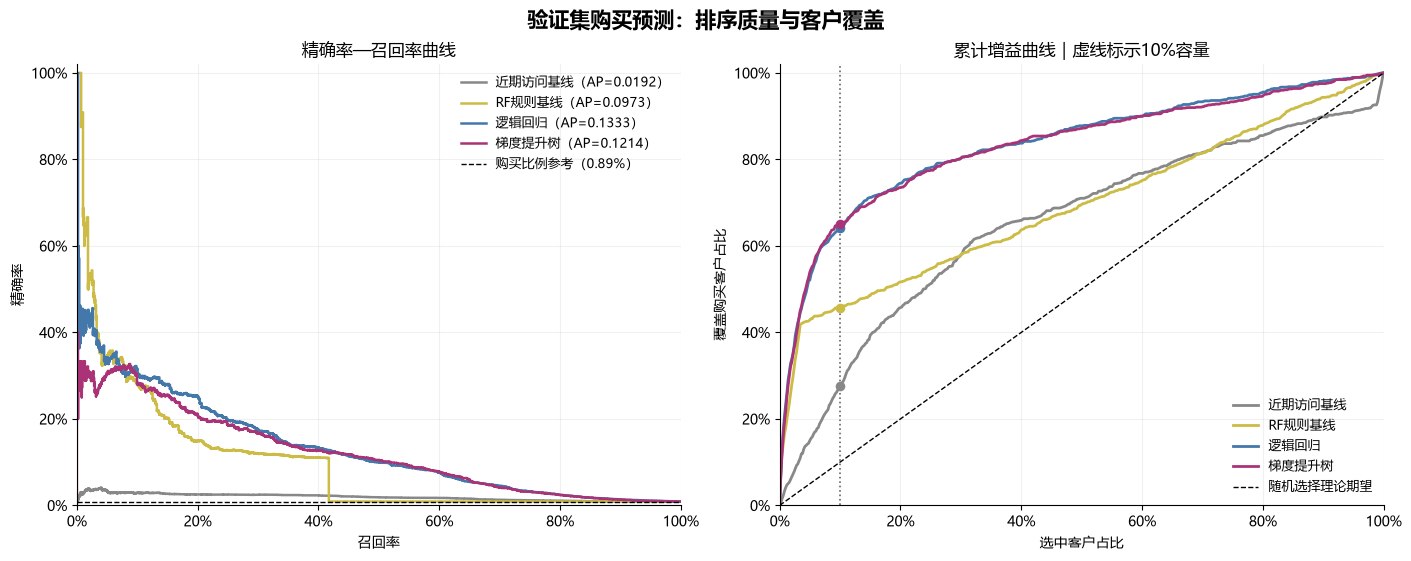

仅展示验证集结果；测试集尚未评价。


In [19]:
from sklearn.metrics import precision_recall_curve
from matplotlib.ticker import PercentFormatter

model_colors = {
    "近期访问基线": "#888888",
    "RF规则基线": "#CCBB44",
    "逻辑回归": "#4477AA",
    "梯度提升树": "#AA3377",
}

y_true = validation_labels.to_numpy()
purchase_rate = y_true.mean()

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    layout="constrained"
)

for method_name, scores in validation_scores.items():
    assert scores.index.equals(validation_labels.index)

    score_values = scores.to_numpy(dtype=float)
    color = model_colors[method_name]

    # 左图：PR曲线，AP仍采用average_precision_score计算
    precision, recall, _ = precision_recall_curve(
        y_true, score_values
    )
    ap = average_precision_score(y_true, score_values)

    axes[0].step(
        recall,
        precision,
        where="post",
        color=color,
        linewidth=1.8,
        label=f"{method_name}（AP={ap:.4f}）"
    )

    # 右图：累计增益，保持与第16格相同的并列处理规则
    rng = np.random.default_rng(random_seed)
    tie_breaker = rng.random(len(y_true))
    order = np.lexsort((tie_breaker, -score_values))

    cumulative_buyers = np.cumsum(y_true[order])

    # 抽取展示点，保留10%位置和最终位置
    top_count = int(np.ceil(len(y_true) * 0.10))
    positions = np.unique(
        np.concatenate([
            np.linspace(
                1, len(y_true), 501
            ).astype(int),
            [top_count, len(y_true)]
        ])
    )

    selected_fraction = positions / len(y_true)
    buyer_coverage = (
        cumulative_buyers[positions - 1] / y_true.sum()
    )

    axes[1].plot(
        np.r_[0, selected_fraction],
        np.r_[0, buyer_coverage],
        color=color,
        linewidth=2,
        label=method_name
    )

    axes[1].scatter(
        top_count / len(y_true),
        cumulative_buyers[top_count - 1] / y_true.sum(),
        color=color,
        s=35,
        zorder=3
    )

# PR参考线
axes[0].axhline(
    purchase_rate,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"购买比例参考（{purchase_rate:.2%}）"
)
axes[0].set_title("精确率—召回率曲线")
axes[0].set_xlabel("召回率")
axes[0].set_ylabel("精确率")

# 累计增益参考线与固定容量
axes[1].plot(
    [0, 1], [0, 1],
    color="black",
    linestyle="--",
    linewidth=1,
    label="随机选择理论期望"
)
axes[1].axvline(
    0.10,
    color="#666666",
    linestyle=":",
    linewidth=1.2
)
axes[1].set_title("累计增益曲线｜虚线标示10%容量")
axes[1].set_xlabel("选中客户占比")
axes[1].set_ylabel("覆盖购买客户占比")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(fontsize=9, frameon=False)

fig.suptitle(
    "验证集购买预测：排序质量与客户覆盖",
    fontsize=15,
    fontweight="bold"
)

fig.savefig(
    figure_folder / "03_validation_ranking_curves.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figure_folder / "03_validation_ranking_curves.pdf",
    bbox_inches="tight"
)

plt.show()
print("仅展示验证集结果；测试集尚未评价。")

### 曲线解读

逻辑回归与梯度提升树的累计增益曲线整体接近，在10%选择容量下分别覆盖约64.03%和65.06%的购买客户。

逻辑回归的AP高于树模型，说明其在该指标下表现更好；
两条累计增益曲线接近，不支持认定其中一个模型全面占优。

PR曲线在极低召回率区域的尖峰可能涉及很少量客户，不能单独作为模型选择依据。

规则基线存在大量并列评分，因此需要检查10%容量边界处的并列客户，判断名单结果对并列处理方式的依赖程度。

## 20. 前10%名单的并列评分敏感性

检查10%选择边界处是否存在大量同分客户。

固定模型评分，仅考虑边界同分客户的不同选择方式，
计算命中买家数的理论最小值、最大值及随机选择期望。

这些上下界是敏感性诊断，不是可实现的营销成绩：
实际选择客户时不能使用未来购买标签打破并列。

本检查不重新训练模型，也不构成模型差异的置信区间。

In [20]:
tie_results = []

y_true = validation_labels.to_numpy()
top_count = int(np.ceil(len(y_true) * 0.10))
total_buyers = int(y_true.sum())

for method_name, scores in validation_scores.items():
    assert scores.index.equals(validation_labels.index)

    values = scores.to_numpy(dtype=float)
    assert np.isfinite(values).all()

    # 第top_count高的评分，即入选边界
    cutoff_score = np.partition(
        values, len(values) - top_count
    )[len(values) - top_count]

    # 精确比较评分，与原评价函数的并列定义保持一致
    above_cutoff = values > cutoff_score
    at_cutoff = values == cutoff_score

    guaranteed_hits = int(y_true[above_cutoff].sum())
    tied_count = int(at_cutoff.sum())
    tied_buyers = int(y_true[at_cutoff].sum())

    remaining_slots = top_count - int(above_cutoff.sum())
    assert 0 < remaining_slots <= tied_count

    # 边界同分客户中，最多能选多少买家、最少必须选多少买家
    min_tied_hits = max(
        0,
        remaining_slots - (tied_count - tied_buyers)
    )
    max_tied_hits = min(remaining_slots, tied_buyers)

    expected_hits = (
        guaranteed_hits
        + remaining_slots * tied_buyers / tied_count
    )

    tie_results.append({
        "方法": method_name,
        "边界同分人数": tied_count,
        "同分组需选人数": remaining_slots,
        "命中数理论下界": guaranteed_hits + min_tied_hits,
        "命中数随机期望": expected_hits,
        "当前固定顺序命中数": int(
            comparison_results.loc[
                method_name, "命中购买客户数"
            ]
        ),
        "命中数理论上界": guaranteed_hits + max_tied_hits,
        "随机期望Recall@10%(%)": (
            expected_hits / total_buyers * 100
        ),
    })

tie_summary = pd.DataFrame(tie_results).set_index("方法")

display(tie_summary.round(3))

print("上下界仅用于诊断，不使用标签决定实际客户名单。")
print("该结果不是模型差异的置信区间；测试集尚未评价。")

,边界同分人数,同分组需选人数,命中数理论下界,命中数随机期望,当前固定顺序命中数,命中数理论上界,随机期望Recall@10%(%)
方法,,,,,,,
近期访问基线,1,1,268,268.000,268,268,27.544
RF规则基线,105168,7194,406,444.786,444,973,45.713
逻辑回归,1,1,623,623.000,623,623,64.029
梯度提升树,1,1,633,633.000,633,633,65.057


上下界仅用于诊断，不使用标签决定实际客户名单。
该结果不是模型差异的置信区间；测试集尚未评价。


### 并列评分检查结果

近期访问、逻辑回归及梯度提升树在10%容量边界处均无并列，因此当前命中人数不受边界同分处理影响。

RF规则存在105,168位边界同分客户，需从中选择7,194位。
其随机选择期望命中数约为444.79，当前命中444位，与期望接近。

RF规则对没有历史购买的客户缺乏进一步区分能力。
理论上下界仅用于说明并列组内结果的可能范围，不能使用未来标签实现该上下界。

逻辑回归与树模型相差10位买家并非并列处理造成，但差异是否稳定仍需进一步验证。

## 21. 重复计数敏感性检查

保持客户、时间窗口、标签、模型参数及预处理方式一致，
仅改变历史事件次数的计算方式：
- 原版本：保留原始事件次数及唯一键次数。
- 敏感性版本：将28天与7天事件次数均改为唯一键次数。

活跃天数、最近行为间隔与行为存在标识不变。
不修改原始样本，也不改变未来购买二元标签。

本实验检验模型表现对计数口径的敏感程度，
不能证明重复键记录一定是错误数据。
搜索唯一键仅包含用户与时间，可能合并不同搜索词，因此该部分仅作为敏感性情景。

In [21]:
from sklearn.base import clone

def replace_with_unique_counts(features, split_name):
    """保留原特征表，另建唯一键计数的敏感性版本。"""
    result = features.copy()

    window = experiment_windows.loc[
        experiment_windows["数据集"].eq(split_name)
    ].iloc[0]

    cutoff_time = window["预测时点"]
    recent_start = cutoff_time - pd.Timedelta(days=7)

    for file_name, prefix in feature_event_names.items():
        event_data = sample_events[file_name]

        # 28天唯一键次数已在第14格计算
        result[f"{prefix}_count_28d"] = (
            result[f"{prefix}_unique_count_28d"]
        )

        # 重新计算7天唯一键次数
        recent_events = event_data.loc[
            event_data["timestamp"].ge(recent_start)
            & event_data["timestamp"].lt(cutoff_time)
            & event_data["client_id"].isin(result.index)
        ]

        unique_recent_count = (
            recent_events.drop_duplicates()
            .groupby("client_id")
            .size()
        )

        result[f"{prefix}_count_7d"] = (
            unique_recent_count.reindex(result.index)
            .fillna(0)
            .astype("int64")
        )

        assert (
            result[f"{prefix}_count_7d"]
            <= result[f"{prefix}_count_28d"]
        ).all()

    assert result.index.equals(features.index)
    assert result.columns.equals(features.columns)
    assert not result.isna().any().any()

    return result


unique_train_features = replace_with_unique_counts(
    train_features, "训练"
)
unique_validation_features = replace_with_unique_counts(
    validation_features, "验证"
)

# clone仅复制配置，不复制已拟合的标准化参数和模型
unique_logistic_model = clone(logistic_model)

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    unique_logistic_model.fit(
        unique_train_features, train_labels
    )

convergence_messages = [
    str(item.message)
    for item in caught_warnings
    if issubclass(item.category, ConvergenceWarning)
]

if convergence_messages:
    raise RuntimeError("\n".join(convergence_messages))

positive_column = list(
    unique_logistic_model.named_steps["model"].classes_
).index(1)

unique_logistic_scores = pd.Series(
    unique_logistic_model.predict_proba(
        unique_validation_features
    )[:, positive_column],
    index=validation_features.index,
    name="unique_logistic_score"
)

unique_logistic_result = pd.DataFrame(
    [evaluate_ranking(
        validation_labels, unique_logistic_scores
    )],
    index=pd.Index(
        ["逻辑回归：唯一键计数情景"],
        name="方法"
    )
)

sensitivity_results = pd.concat([
    logistic_result.rename(
        index={"逻辑回归": "逻辑回归：原计数版本"}
    ),
    unique_logistic_result
])

print("验证集：重复计数敏感性比较")
display(sensitivity_results.round(4))

print(
    "敏感性模型迭代次数：",
    unique_logistic_model.named_steps["model"].n_iter_
)
print("原始样本与原模型均未修改；测试集尚未评价。")

验证集：重复计数敏感性比较


,AP,ROC-AUC,选中客户数,命中购买客户数,Precision@10%(%),Recall@10%(%),Lift@10%
方法,,,,,,,
逻辑回归：原计数版本,0.1333,0.8377,10886,623,5.7229,64.0288,6.4029
逻辑回归：唯一键计数情景,0.1330,0.8382,10886,621,5.7046,63.8232,6.3823


敏感性模型迭代次数： [29]
原始样本与原模型均未修改；测试集尚未评价。


### 重复计数敏感性结果

原计数版本的AP为0.1333，唯一键计数情景为0.1300。
在相同10%容量下，命中购买客户数分别为623和621，
Recall@10%相差约0.21个百分点。

本次验证结果对计数口径变化较稳定，
未观察到模型表现因采用唯一键计数而大幅下降。

这不证明重复键记录是错误或完全无影响；
搜索唯一键还可能合并同一时点的不同搜索词。
保留原计数版本作为候选主模型，唯一键版本作为敏感性对照。

## 22. 验证集模型差异的配对Bootstrap检查

以客户为单位进行500次有放回重采样。
每次对逻辑回归和树模型使用相同的客户样本，
重新计算AP及前10%客户覆盖率。

统一计算“逻辑回归减去梯度提升树”的差值，
使用重采样差值的2.5%和97.5%分位数构造近似95%区间。

解释：
- 区间全部大于0：本次重采样支持逻辑回归在该指标上较高。
- 区间全部小于0：支持树模型在该指标上较高。
- 区间包含0：当前证据不足以明确区分两者。

区间仅反映固定模型、当前验证窗口下的客户抽样不确定性。
它不涵盖重新训练的不确定性、未来时间漂移或模型选择偏差，并依赖客户之间近似独立的假设。

In [22]:
bootstrap_repeats = 500
bootstrap_rng = np.random.default_rng(random_seed)

assert logistic_scores.index.equals(validation_labels.index)
assert tree_scores.index.equals(validation_labels.index)

bootstrap_y = validation_labels.to_numpy()
bootstrap_lr = logistic_scores.to_numpy(dtype=float)
bootstrap_tree = tree_scores.to_numpy(dtype=float)


def bootstrap_metrics(y, scores, tie_breaker):
    """在当前重采样中重新选取评分最高的10%客户。"""
    selected_count = int(np.ceil(len(y) * 0.10))
    order = np.lexsort((tie_breaker, -scores))

    recall_at_10 = (
        y[order[:selected_count]].sum() / y.sum()
    )

    return (
        average_precision_score(y, scores),
        recall_at_10
    )


bootstrap_differences = []

for repeat in range(bootstrap_repeats):
    # 同一组客户抽样同时用于两个模型，保留配对关系
    positions = bootstrap_rng.integers(
        0, len(bootstrap_y), size=len(bootstrap_y)
    )

    sampled_y = bootstrap_y[positions]

    if np.unique(sampled_y).size < 2:
        continue

    # 重采样可能产生重复评分，统一使用无标签随机顺序
    tie_breaker = bootstrap_rng.random(len(sampled_y))

    lr_ap, lr_recall = bootstrap_metrics(
        sampled_y,
        bootstrap_lr[positions],
        tie_breaker
    )

    tree_ap, tree_recall = bootstrap_metrics(
        sampled_y,
        bootstrap_tree[positions],
        tie_breaker
    )

    bootstrap_differences.append({
        "AP差值": lr_ap - tree_ap,
        "Recall@10%差值(百分点)": (
            lr_recall - tree_recall
        ) * 100,
    })

    if (repeat + 1) % 100 == 0:
        print(
            f"已完成 {repeat + 1}/{bootstrap_repeats} 次",
            flush=True
        )

bootstrap_differences = pd.DataFrame(bootstrap_differences)

observed_differences = {
    "AP差值": (
        logistic_result.loc["逻辑回归", "AP"]
        - tree_result.loc["梯度提升树", "AP"]
    ),
    "Recall@10%差值(百分点)": (
        logistic_result.loc["逻辑回归", "Recall@10%(%)"]
        - tree_result.loc["梯度提升树", "Recall@10%(%)"]
    ),
}

bootstrap_rows = []

for metric_name, observed_value in observed_differences.items():
    lower, upper = np.quantile(
        bootstrap_differences[metric_name],
        [0.025, 0.975]
    )

    bootstrap_rows.append({
        "指标（逻辑回归－树模型）": metric_name,
        "原验证集差值": observed_value,
        "近似95%区间下界": lower,
        "近似95%区间上界": upper,
        "区间是否包含0": lower <= 0 <= upper,
    })

bootstrap_summary = pd.DataFrame(bootstrap_rows)

print("\n配对Bootstrap差异检查：")
display(bootstrap_summary.round(4))
print("有效重采样次数：", len(bootstrap_differences))
print("模型未重新训练；测试集尚未评价。")

已完成 100/500 次
已完成 200/500 次
已完成 300/500 次
已完成 400/500 次
已完成 500/500 次

配对Bootstrap差异检查：


,指标（逻辑回归－树模型）,原验证集差值,近似95%区间下界,近似95%区间上界,区间是否包含0
0,AP差值,0.0119,0.0017,0.0212,False
1,Recall@10%差值(百分点),-1.0277,-2.6428,0.4049,True


有效重采样次数： 500
模型未重新训练；测试集尚未评价。


### 配对Bootstrap结果与模型选择

完成500次客户级配对Bootstrap。

逻辑回归减去树模型的AP差值为0.0119，近似95%区间为[0.0017，0.0212]，未包含0。

Recall@10%的差值为−1.0277个百分点，近似95%区间为[−2.6428，0.4049]，包含0。

在当前验证窗口、固定模型及客户近似独立的假设下，结果支持逻辑回归的AP较高，但不足以确认树模型在10%容量下更优。

结合主要指标AP、重复计数敏感性和模型简洁性，固定原计数版本的逻辑回归为主模型。
树模型保留为对照，不根据测试结果重新选择主模型。

## 23. 固定模型与最终时间测试

主模型固定为原计数版本的逻辑回归：
- 使用原有30个历史特征。
- 保留训练阶段拟合的变换、标准化参数及模型。
- 不重新训练，不使用测试标签调整参数。
- 固定选择评分最高的10%客户，并列时使用固定随机顺序。

测试标签窗口：
2022年11月24日零点至12月8日零点之前。

同时评价预先确定的近期访问、RF规则与梯度提升树，用于完整报告比较结果，不根据测试成绩更换主模型。

本次采用时间留出测试，允许同一客户跨窗口出现，评价的是后续时段活跃客户，不代表完全陌生客户的泛化能力。

完成测试后，不根据测试结果修改方案并反复测试。

In [23]:
# 在生成测试标签前，明确固定最终方案
final_model = logistic_model
final_model_name = "逻辑回归"
selection_fraction = 0.10

print("固定主模型：", final_model_name)
print("特征数量：", train_features.shape[1])
print("选择容量：10%")
print("本次不重新训练模型。")

# 先生成预测评分，再生成标签
lr_positive_column = list(
    final_model.named_steps["model"].classes_
).index(1)

test_logistic_scores = pd.Series(
    final_model.predict_proba(test_features)[
        :, lr_positive_column
    ],
    index=test_features.index
)

tree_positive_column = list(tree_model.classes_).index(1)

test_tree_scores = pd.Series(
    tree_model.predict_proba(test_features)[
        :, tree_positive_column
    ],
    index=test_features.index
)

# RF规则沿用相同排序定义：
# 买过优先、购买活跃天数多优先、最近购买间隔短优先
rf_columns = [
    "buy_has_event_28d",
    "buy_active_days_28d",
    "buy_recency_days",
]

test_rf_levels = (
    test_features[rf_columns]
    .drop_duplicates()
    .sort_values(
        rf_columns,
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)
test_rf_levels["rf_score"] = np.arange(
    len(test_rf_levels), dtype=float
)

test_rf_scores = (
    test_features[rf_columns]
    .reset_index()
    .merge(
        test_rf_levels,
        on=rf_columns,
        how="left",
        validate="many_to_one"
    )
    .set_index("client_id")["rf_score"]
    .reindex(test_features.index)
)

test_scores = {
    "近期访问基线": -test_features["visit_recency_days"],
    "RF规则基线": test_rf_scores,
    "逻辑回归": test_logistic_scores,
    "梯度提升树": test_tree_scores,
}

# 首次构造测试标签
test_labels = build_purchase_label(
    "测试", test_features.index
)

assert test_labels.index.equals(test_features.index)
assert test_labels.nunique() == 2

test_result_rows = []

for method_name, scores in test_scores.items():
    result = evaluate_ranking(
        test_labels,
        scores,
        top_fraction=selection_fraction
    )
    result["方法"] = method_name
    test_result_rows.append(result)

test_results = (
    pd.DataFrame(test_result_rows)
    .set_index("方法")
)

print("\n测试集标签概况：")
print(f"客户总数：{len(test_labels):,}")
print(f"未来14天购买客户数：{int(test_labels.sum()):,}")
print(f"购买客户比例：{test_labels.mean():.4%}")

print("\n最终时间测试结果：")
display(test_results.round(4))

# 保存本地结果，不覆盖此前验证成绩
test_results.to_csv(
    feature_folder / "test_results.csv",
    encoding="utf-8-sig"
)

test_predictions = pd.DataFrame({
    "client_id": test_features.index.to_numpy(),
    "target_buy_14d": test_labels.to_numpy(),
    "logistic_score": test_logistic_scores.to_numpy(),
    "tree_score": test_tree_scores.to_numpy(),
})

test_predictions.to_parquet(
    feature_folder / "test_predictions.parquet",
    index=False
)

print("\n测试结果与预测记录已保存到：", feature_folder)

固定主模型： 逻辑回归
特征数量： 30
选择容量：10%
本次不重新训练模型。

测试集标签概况：
客户总数：117,048
未来14天购买客户数：1,198
购买客户比例：1.0235%

最终时间测试结果：


,AP,ROC-AUC,选中客户数,命中购买客户数,Precision@10%(%),Recall@10%(%),Lift@10%
方法,,,,,,,
近期访问基线,0.0267,0.6816,11705,377,3.2208,31.4691,3.1469
RF规则基线,0.1180,0.7029,11705,571,4.8783,47.6628,4.7662
逻辑回归,0.1688,0.8645,11705,816,6.9714,68.1135,6.8112
梯度提升树,0.1579,0.8620,11705,816,6.9714,68.1135,6.8112



测试结果与预测记录已保存到： D:\course\data analysis\group project\ecommerce-customer-analysis\data\processed\sample_v1\features


### 最终时间测试结果

测试集包含117,048位历史活跃客户，其中1,198位在未来14天内出现购买，购买比例为1.0235%。

固定的逻辑回归模型：
- AP为0.1688，ROC-AUC为0.8645。
- 选出11,705位客户，命中816位买家。
- Precision@10%为6.97%，Recall@10%为68.11%。
- Lift@10%为6.81，即入选客户购买比例约为总体的6.81倍。

相同容量下，逻辑回归比RF规则多命中245位买家，覆盖率提高约20.45个百分点。

树模型在10%容量下同样命中816位买家，但AP低于逻辑回归。
主模型继续采用测试前已确定的逻辑回归，不根据测试结果更换。

结果支持该模型在本次后续时间窗口中的排序价值，不代表营销干预产生了新增购买。
测试期整体购买比例高于验证期，不能只根据AP上升认定模型变强。

## 24. 固定10%容量下的错误分析

按已固定的评分排序规则，将前10%客户标记为入选，并检查入选与实际购买的交叉分布。

这里的“入选”是容量决策，不是以0.5为阈值的概率分类。

关注：
- 入选但未购买：客户维护可能触达的非买家。
- 未入选但购买：固定容量下遗漏的买家。

进一步按历史28天是否购买分组，检查不同客户群的覆盖情况。
该分组只用于诊断，不用于修改已完成的模型或测试方案。

固定10%容量下的结果：


,结果,客户数
0,入选且购买,816
1,入选但未购买,10889
2,未入选但购买,382
3,未入选且未购买,104961



按历史购买情况分组的诊断：


,客户群,客户数,实际购买客户数,入选客户数,命中买家数,群体购买比例(%),群体买家覆盖率(%),入选客户购买比例(%)
0,历史28天未买过,112960,679,7622,297,0.601,43.741,3.897
1,历史28天买过,4088,519,4083,519,12.696,100.000,12.711


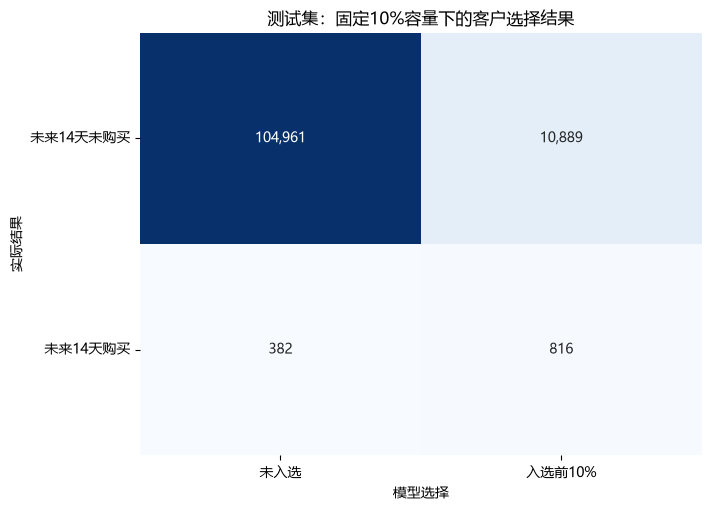

In [24]:
# 与第15格评价函数保持完全相同的排序和并列处理方式
assert test_labels.index.equals(test_logistic_scores.index)

scores = test_logistic_scores.to_numpy(dtype=float)
actual = test_labels.to_numpy()
selected_count = int(np.ceil(len(actual) * selection_fraction))

rng = np.random.default_rng(random_seed)
tie_breaker = rng.random(len(actual))
order = np.lexsort((tie_breaker, -scores))

selected = np.zeros(len(actual), dtype=bool)
selected[order[:selected_count]] = True

# 构造诊断表；不改变特征、模型和预测评分
test_diagnostics = pd.DataFrame({
    "实际购买": actual,
    "入选": selected,
    "预测评分": scores,
    "历史购买分组": np.where(
        test_features["buy_has_event_28d"].to_numpy() == 1,
        "历史28天买过",
        "历史28天未买过"
    ),
}, index=test_features.index)

hit = int((selected & (actual == 1)).sum())
not_buy_selected = int((selected & (actual == 0)).sum())
missed = int((~selected & (actual == 1)).sum())
not_buy_unselected = int((~selected & (actual == 0)).sum())

assert hit == int(
    test_results.loc["逻辑回归", "命中购买客户数"]
)

error_summary = pd.DataFrame([
    {"结果": "入选且购买", "客户数": hit},
    {"结果": "入选但未购买", "客户数": not_buy_selected},
    {"结果": "未入选但购买", "客户数": missed},
    {"结果": "未入选且未购买", "客户数": not_buy_unselected},
])

print("固定10%容量下的结果：")
display(error_summary)

group_rows = []

for group_name, group in test_diagnostics.groupby(
    "历史购买分组", sort=False
):
    group_buyers = int(group["实际购买"].sum())
    group_selected = int(group["入选"].sum())
    group_hits = int(
        (group["入选"] & group["实际购买"].eq(1)).sum()
    )

    group_rows.append({
        "客户群": group_name,
        "客户数": len(group),
        "实际购买客户数": group_buyers,
        "入选客户数": group_selected,
        "命中买家数": group_hits,
        "群体购买比例(%)": group_buyers / len(group) * 100,
        "群体买家覆盖率(%)": (
            group_hits / group_buyers * 100
            if group_buyers else np.nan
        ),
        "入选客户购买比例(%)": (
            group_hits / group_selected * 100
            if group_selected else np.nan
        ),
    })

group_diagnostics = pd.DataFrame(group_rows)

print("\n按历史购买情况分组的诊断：")
display(group_diagnostics.round(3))

# 绘制容量决策的交叉分布图
decision_matrix = np.array([
    [not_buy_unselected, not_buy_selected],
    [missed, hit],
])

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")

sns.heatmap(
    decision_matrix,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["未入选", "入选前10%"],
    yticklabels=["未来14天未购买", "未来14天购买"],
    ax=ax
)

ax.set_title("测试集：固定10%容量下的客户选择结果")
ax.set_xlabel("模型选择")
ax.set_ylabel("实际结果")
ax.tick_params(axis="y", rotation=0)

fig.savefig(
    figure_folder / "04_test_selection_outcomes.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figure_folder / "04_test_selection_outcomes.pdf",
    bbox_inches="tight"
)

plt.show()

### 客户选择与分组诊断结果

固定选择前10%客户时，共命中816位买家，遗漏382位买家，入选但未购买的客户为10,889位。

历史28天买过的4,088位客户中，4,083位入选；
该群体的519位未来买家全部被覆盖。
这是本次测试窗口的结果，不能外推为长期100%覆盖。

历史28天未买过的112,960位客户中，7,622位入选，覆盖679位未来买家中的297位，覆盖率为43.74%。
遗漏的382位买家全部来自该群体。

模型能够识别部分没有近期购买记录的未来买家，但这一群体仍是主要遗漏来源。
历史28天未购买不等于新客户或从未购买。

入选客户购买比例为6.97%，多数入选客户仍未购买。
是否值得触达还需考虑成本、利润和干预的增量效果。

## 25. 行为组置换重要性

将页面访问、搜索、加购、移出购物车及购买分别作为特征组。
每次使用同一随机排列，同时打乱一组内的全部特征，保留组内特征之间的对应关系，观察测试AP的变化。

每组重复5次。
重要性=原测试AP-打乱后的AP。

数值越大，表示固定模型对该行为组的信息依赖越强。
负值表示打乱后AP反而提高，可能与噪声或模型局限有关。

该分析仅用于最终模型解释，不再用于特征选择或重新训练。
不同行为组可能相关，重要性不等于因果影响；重复间标准差也不是正式置信区间。

完成：页面访问
完成：搜索
完成：加购
完成：移出购物车
完成：购买


,行为组,特征数,AP下降均值,重复间标准差
0,页面访问,6,0.05993,0.00426
1,购买,6,0.05640,0.00227
2,加购,6,0.02275,0.00131
3,搜索,6,0.01507,0.00194
4,移出购物车,6,-0.00669,0.00029


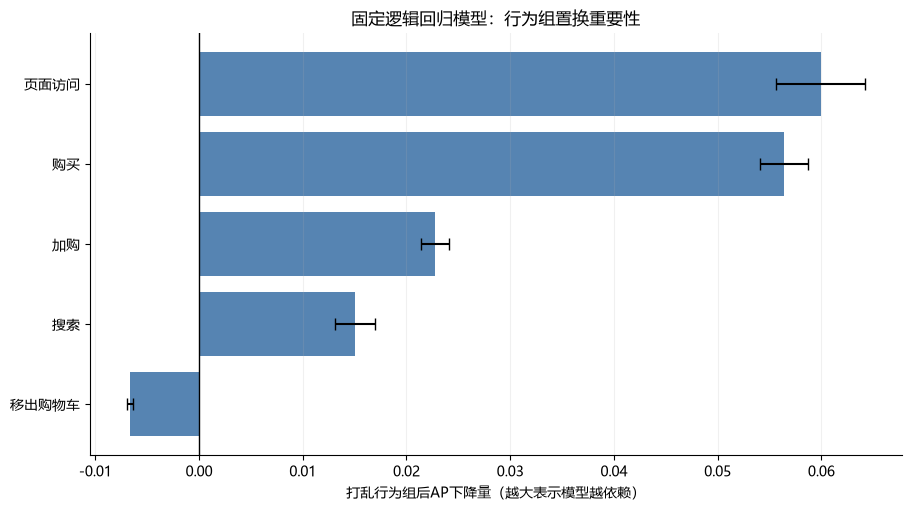

误差线为重复间标准差；模型未重新训练。


In [25]:
# 固定模型；仅打乱输入，不重新训练
behavior_groups = {
    "页面访问": "visit",
    "搜索": "search",
    "加购": "cart",
    "移出购物车": "remove",
    "购买": "buy",
}

importance_repeats = 5
importance_rng = np.random.default_rng(random_seed)

# 各组使用相同的排列集合，便于比较
permutations = [
    importance_rng.permutation(len(test_features))
    for _ in range(importance_repeats)
]

original_ap = average_precision_score(
    test_labels, test_logistic_scores
)

positive_column = list(
    final_model.named_steps["model"].classes_
).index(1)

importance_rows = []

for group_name, prefix in behavior_groups.items():
    group_columns = [
        column for column in test_features.columns
        if column.startswith(f"{prefix}_")
    ]

    ap_drops = []

    for positions in permutations:
        shuffled_features = test_features.copy()

        # 同组所有字段一起打乱，保持组内组合一致
        shuffled_features[group_columns] = (
            test_features.iloc[positions][group_columns]
            .to_numpy()
        )

        shuffled_scores = final_model.predict_proba(
            shuffled_features
        )[:, positive_column]

        shuffled_ap = average_precision_score(
            test_labels, shuffled_scores
        )

        ap_drops.append(original_ap - shuffled_ap)

    importance_rows.append({
        "行为组": group_name,
        "特征数": len(group_columns),
        "AP下降均值": np.mean(ap_drops),
        "重复间标准差": np.std(ap_drops, ddof=1),
    })

    print(f"完成：{group_name}", flush=True)

behavior_importance = (
    pd.DataFrame(importance_rows)
    .sort_values("AP下降均值", ascending=False)
    .reset_index(drop=True)
)

display(behavior_importance.round(5))

# 水平条形图：误差线表示5次置换间的标准差
plot_data = behavior_importance.sort_values("AP下降均值")

fig, ax = plt.subplots(
    figsize=(9, 5),
    layout="constrained"
)

ax.barh(
    plot_data["行为组"],
    plot_data["AP下降均值"],
    xerr=plot_data["重复间标准差"],
    color="#4477AA",
    capsize=4,
    alpha=0.9
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("打乱行为组后AP下降量（越大表示模型越依赖）")
ax.set_title("固定逻辑回归模型：行为组置换重要性")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.18)

fig.savefig(
    figure_folder / "05_behavior_group_importance.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figure_folder / "05_behavior_group_importance.pdf",
    bbox_inches="tight"
)

plt.show()
print("误差线为重复间标准差；模型未重新训练。")

### 行为组重要性解释

页面访问和历史购买的置换AP下降量最大，分别约为0.05993和0.05640，说明固定逻辑回归模型较依赖这两组历史行为信息。
加购和搜索也提供一定预测信息。

移出购物车组的重要性为负，打乱后AP平均提高约0.00669。
这提示该组在当前模型与测试窗口中的利用可能存在局限，但不能解释为因果关系，也不足以证明该行为组没有预测价值。

行为组之间可能相关，置换会破坏跨组关系，因此重要性不是各组贡献的可加分解，不能相加为100%。

本次结果仅用于模型解释，不据此修改已完成测试的模型。

## 26. 基于历史行为的客户分群画像

在测试预测时点，根据此前28天的历史行为划分四类客户：

1. 近期多日购买：购买活跃天数至少2天。
2. 近期单日购买：购买活跃天数为1天。
3. 无购买但有加购：无购买记录，但出现加购。
4. 无购买且无加购：既无购买记录，也无加购记录。

四组互斥且覆盖全部测试客户。
采用购买活跃天数，而非原始购买次数，减少相同时间重复记录的影响。

分群规则为描述性业务规则，不是自然聚类结果。
“无购买”仅指历史28天未观察到购买。

未来14天购买比例用于事后比较，不用于定义分组、
改变模型、重新分配10%选择容量或制定已验证的营销方案。

,客户数,未来购买客户数,入选客户数,平均访问活跃天数,平均加购活跃天数,平均购买活跃天数,客户占比(%),未来14天购买比例(%),群体入选比例(%)
客户分群,,,,,,,,,
近期多日购买,483,151,483,6.698,2.822,2.393,0.413,31.263,100.000
近期单日购买,3605,368,3600,2.655,0.885,1.000,3.080,10.208,99.861
无购买但有加购,8154,233,4789,2.637,1.191,0.000,6.966,2.857,58.732
无购买且无加购,104806,446,2833,1.440,0.000,0.000,89.541,0.426,2.703


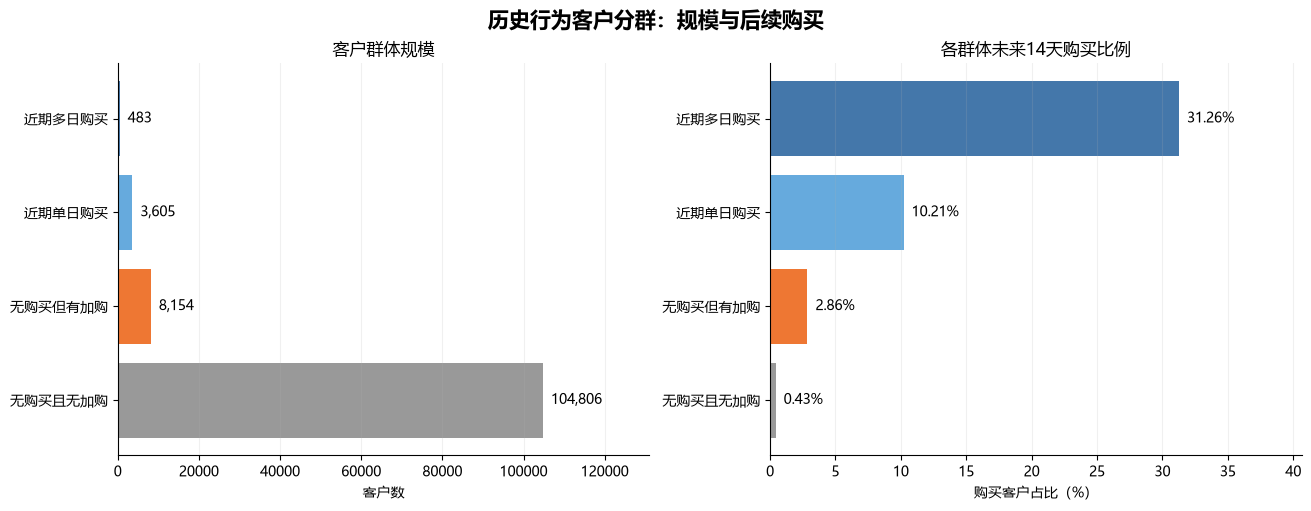

In [26]:
# 分群只使用历史特征，不使用未来标签或模型评分
customer_segments = pd.Series(
    np.select(
        [
            test_features["buy_active_days_28d"].ge(2),
            test_features["buy_active_days_28d"].eq(1),
            (
                test_features["buy_has_event_28d"].eq(0)
                & test_features["cart_has_event_28d"].eq(1)
            ),
        ],
        [
            "近期多日购买",
            "近期单日购买",
            "无购买但有加购",
        ],
        default="无购买且无加购"
    ),
    index=test_features.index,
    name="客户分群"
)

segment_order = [
    "近期多日购买",
    "近期单日购买",
    "无购买但有加购",
    "无购买且无加购",
]

segment_data = pd.DataFrame({
    "客户分群": customer_segments,
    "未来14天购买": test_labels,
    "入选": test_diagnostics["入选"],
    "访问活跃天数": test_features["visit_active_days_28d"],
    "加购活跃天数": test_features["cart_active_days_28d"],
    "购买活跃天数": test_features["buy_active_days_28d"],
})

segment_summary = (
    segment_data.groupby("客户分群")
    .agg(
        客户数=("未来14天购买", "size"),
        未来购买客户数=("未来14天购买", "sum"),
        入选客户数=("入选", "sum"),
        平均访问活跃天数=("访问活跃天数", "mean"),
        平均加购活跃天数=("加购活跃天数", "mean"),
        平均购买活跃天数=("购买活跃天数", "mean"),
    )
    .reindex(segment_order)
)

# 核验四组覆盖全部客户及买家
assert segment_summary["客户数"].sum() == len(test_features)
assert (
    segment_summary["未来购买客户数"].sum()
    == test_labels.sum()
)

segment_summary["客户占比(%)"] = (
    segment_summary["客户数"] / len(test_features) * 100
)
segment_summary["未来14天购买比例(%)"] = (
    segment_summary["未来购买客户数"]
    / segment_summary["客户数"] * 100
)
segment_summary["群体入选比例(%)"] = (
    segment_summary["入选客户数"]
    / segment_summary["客户数"] * 100
)

display(segment_summary.round(3))

# 同时展示群体规模和未来购买比例，避免只看比例忽略人数
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    layout="constrained"
)

positions = np.arange(len(segment_order))
colors = ["#4477AA", "#66AADD", "#EE7733", "#999999"]

customer_counts = segment_summary["客户数"].to_numpy()
purchase_rates = (
    segment_summary["未来14天购买比例(%)"].to_numpy()
)

axes[0].barh(positions, customer_counts, color=colors)
axes[1].barh(positions, purchase_rates, color=colors)

for ax in axes:
    ax.set_yticks(positions, labels=segment_order)
    ax.invert_yaxis()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", alpha=0.18)

axes[0].set_title("客户群体规模")
axes[0].set_xlabel("客户数")
axes[0].set_xlim(0, max(customer_counts.max() * 1.25, 1))

axes[1].set_title("各群体未来14天购买比例")
axes[1].set_xlabel("购买客户占比（%）")
axes[1].set_xlim(0, max(purchase_rates.max() * 1.3, 1))

for position, count in zip(positions, customer_counts):
    axes[0].text(
        count, position, f"  {int(count):,}", va="center"
    )

for position, rate in zip(positions, purchase_rates):
    if np.isfinite(rate):
        axes[1].text(
            rate, position, f"  {rate:.2f}%", va="center"
        )

fig.suptitle(
    "历史行为客户分群：规模与后续购买",
    fontsize=15,
    fontweight="bold"
)

fig.savefig(
    figure_folder / "06_customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figure_folder / "06_customer_segments.pdf",
    bbox_inches="tight"
)

plt.show()

### 客户分群结果

历史28天内在至少两个日期购买的客户有483位，未来14天购买比例为31.26%；单日购买群体为10.21%。

历史28天无购买但有加购的群体有8,154位，未来购买比例为2.86%。

无购买且无加购群体占全部客户的89.54%，购买比例仅约0.43%，但由于规模较大，仍包含446位未来买家，占全部未来买家的约37.23%。

因此，群体购买比例与买家总量需要同时考虑。
不能简单忽略规模较大的低购买比例群体。

分群体现历史行为与未来购买的关联，不能证明加购或增加购买天数能够导致未来购买。
群体入选比例反映当前固定模型的选择结果，不是最优资源配置。

## 27. 历史购买类目的客户覆盖

分析测试窗口入选客户在预测时点之前28天的购买类目，即2022年10月27日至11月24日零点之前。

按各类目的不同购买客户数排名，展示前十名。
同一客户在同一类目重复购买只计一人，但购买多个类目时可以计入多个类目。

类目客户覆盖率=购买该类目的不同客户数/历史购买客户总数。

不同类目的覆盖率不能相加解释为100%。
类目为匿名编号，不推测真实商品名称；样本结果不代表平台全量销量或市场份额。

历史28天购买客户数：4,088
历史购买涉及类目数：1,656


,category,不同购买客户数,历史买家覆盖率(%)
60,258,125,3.058
979,4092,57,1.394
275,1096,54,1.321
715,2964,52,1.272
1562,6573,50,1.223
191,791,46,1.125
749,3138,45,1.101
5,37,42,1.027
1514,6356,39,0.954
291,1135,38,0.930


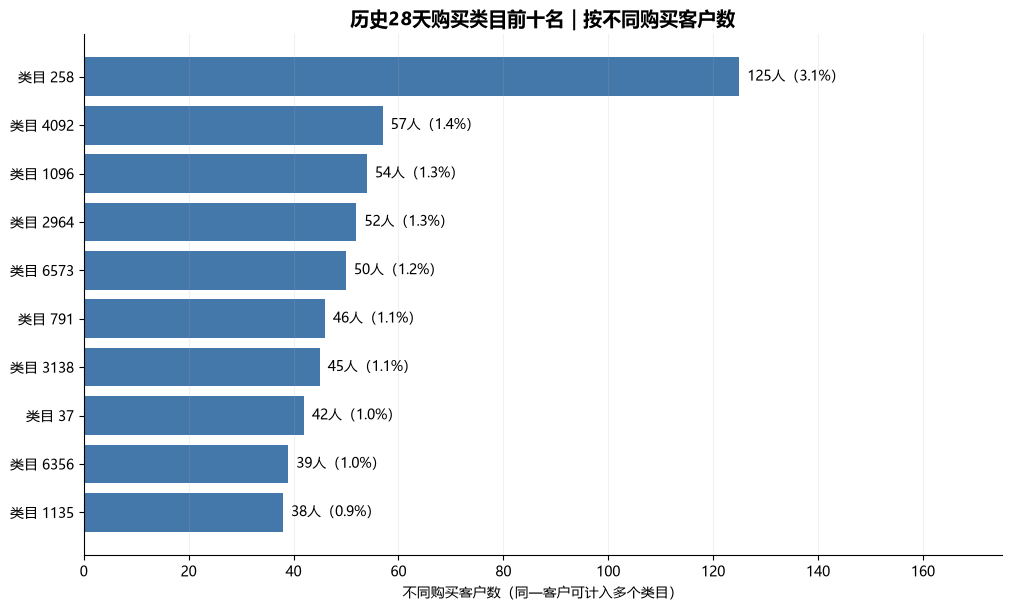

In [27]:
# 使用测试预测前的历史窗口
test_window = experiment_windows.loc[
    experiment_windows["数据集"].eq("测试")
].iloc[0]

buy_events = sample_events["product_buy.parquet"]

historical_buys = buy_events.loc[
    buy_events["timestamp"].ge(test_window["特征开始"])
    & buy_events["timestamp"].lt(test_window["预测时点"])
    & buy_events["client_id"].isin(test_features.index)
].copy()

# 关联商品类目，并验证不会扩增行为行数
historical_buy_categories = historical_buys.merge(
    product_properties[["sku", "category"]],
    on="sku",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(historical_buy_categories) == len(historical_buys)
assert historical_buy_categories["_merge"].eq("both").all()
assert historical_buy_categories["category"].notna().all()

historical_buyer_count = historical_buys["client_id"].nunique()

assert historical_buyer_count == int(
    test_features["buy_has_event_28d"].sum()
)

# 一位客户在同一类目只计一次，避免重复事件增加人数
customer_category_pairs = (
    historical_buy_categories[
        ["client_id", "category"]
    ]
    .drop_duplicates()
)

category_summary = (
    customer_category_pairs.groupby("category")
    .size()
    .rename("不同购买客户数")
    .reset_index()
    .sort_values(
        ["不同购买客户数", "category"],
        ascending=[False, True]
    )
)

category_summary["历史买家覆盖率(%)"] = (
    category_summary["不同购买客户数"]
    / historical_buyer_count * 100
)

category_top10 = category_summary.head(10).copy()

print(f"历史28天购买客户数：{historical_buyer_count:,}")
print(f"历史购买涉及类目数：{len(category_summary):,}")
display(category_top10.round(3))

# 最大值显示在上方
plot_categories = category_top10.iloc[::-1]

fig, ax = plt.subplots(
    figsize=(10, 6),
    layout="constrained"
)

labels = [
    f"类目 {int(value)}"
    for value in plot_categories["category"]
]

ax.barh(
    labels,
    plot_categories["不同购买客户数"],
    color="#4477AA"
)

for position, (_, row) in enumerate(plot_categories.iterrows()):
    ax.text(
        row["不同购买客户数"],
        position,
        f"  {int(row['不同购买客户数']):,}人"
        f"（{row['历史买家覆盖率(%)']:.1f}%）",
        va="center"
    )

ax.set_xlim(
    0,
    category_top10["不同购买客户数"].max() * 1.4
)
ax.set_title(
    "历史28天购买类目前十名｜按不同购买客户数",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("不同购买客户数（同一客户可计入多个类目）")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.18)

fig.savefig(
    figure_folder / "07_top_purchase_categories.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figure_folder / "07_top_purchase_categories.pdf",
    bbox_inches="tight"
)

plt.show()

### 历史购买类目结果

测试预测时点之前28天内，4,088位历史买家涉及1,656个商品类目。

按不同购买客户数排名，类目258位居第一，覆盖125位买家，占历史买家的3.06%；其余前十名类目的覆盖率约为0.93%—1.39%。

这些结果描述当前用户样本的历史购买分布，不代表全平台销量、市场份额或未来需求。

客户可以购买多个类目，因此不同类目的客户覆盖率不可直接相加，若需计算前十名的联合覆盖率，应重新对客户去重。

## 28. 导出分析结果与运行环境

将汇总表保存到 `reports/tables/`，用于报告与汇报。
这里只导出汇总统计，不导出客户编号、客户名单或个人预测记录。

根据当前Notebook内核记录项目直接依赖的版本，并保存Python及操作系统信息。

环境清单记录实际版本，不代表已经完成其他电脑上的兼容性验证。
最终还需重启内核、从头运行Notebook，检查复现结果。

In [28]:
from importlib.metadata import version
import platform

table_folder = project_folder / "reports" / "tables"
table_folder.mkdir(parents=True, exist_ok=True)

# 统一导出已有汇总表，不包含客户级明细
summary_tables = {
    "01_time_quality": time_summary,
    "02_product_quality": product_quality,
    "03_daily_coverage": coverage_summary,
    "04_period_comparison": trend_comparison,
    "05_weekday_mean": weekday_mean,
    "06_sku_matching": sku_match_summary,
    "07_experiment_windows": experiment_windows,
    "08_user_quality": user_quality_summary,
    "09_sample_counts": sample_summary,
    "10_sample_extraction": extraction_summary,
    "11_sample_quality": sample_check_summary,
    "12_eligibility": eligibility_summary,
    "13_development_labels": pd.DataFrame(label_summary),
    "14_validation_models": comparison_results,
    "15_tie_sensitivity": tie_summary,
    "16_duplicate_sensitivity": sensitivity_results,
    "17_bootstrap_difference": bootstrap_summary,
    "18_test_models": test_results,
    "19_selection_outcomes": error_summary,
    "20_group_diagnostics": group_diagnostics,
    "21_behavior_importance": behavior_importance,
    "22_customer_segments": segment_summary,
    "23_purchase_categories": category_summary,
}

for file_name, table in summary_tables.items():
    table.to_csv(
        table_folder / f"{file_name}.csv",
        index=True,
        encoding="utf-8-sig"
    )

# 记录实际使用的直接依赖，不导出整个全局环境
dependencies = [
    "numpy",
    "pandas",
    "pyarrow",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "ipython",
    "ipykernel",
]

requirements_text = "\n".join(
    f"{package}=={version(package)}"
    for package in dependencies
) + "\n"

# 使用单独文件名，保留已有requirements.txt
requirements_path = project_folder / "requirements-verified.txt"
requirements_path.write_text(
    requirements_text,
    encoding="utf-8"
)

environment_info = {
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "dependencies": {
        package: version(package)
        for package in dependencies
    },
    "main_model": "原计数版本逻辑回归",
    "selection_fraction": selection_fraction,
    "random_seed": random_seed,
    "sample_percent": sample_percent,
    "reproduction_status": "待重启内核后完整运行验证",
}

environment_path = (
    project_folder / "reports" / "environment.json"
)
environment_path.write_text(
    json.dumps(environment_info, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# 核验此前7组图表是否齐全
figure_names = [
    "01_daily_behavior_trends",
    "02_weekday_behavior_heatmap",
    "03_validation_ranking_curves",
    "04_test_selection_outcomes",
    "05_behavior_group_importance",
    "06_customer_segments",
    "07_top_purchase_categories",
]

figure_check = pd.DataFrame([
    {
        "图表": name,
        "PNG存在": (figure_folder / f"{name}.png").exists(),
        "PDF存在": (figure_folder / f"{name}.pdf").exists(),
    }
    for name in figure_names
])

print(f"已导出汇总表：{len(summary_tables)}份")
print("表格位置：", table_folder)
print("依赖版本文件：", requirements_path)
print("运行环境记录：", environment_path)

print("\n图表文件检查：")
display(figure_check)

已导出汇总表：23份
表格位置： D:\course\data analysis\group project\ecommerce-customer-analysis\reports\tables
依赖版本文件： D:\course\data analysis\group project\ecommerce-customer-analysis\requirements-verified.txt
运行环境记录： D:\course\data analysis\group project\ecommerce-customer-analysis\reports\environment.json

图表文件检查：


,图表,PNG存在,PDF存在
0,01_daily_behavior_trends,True,True
1,02_weekday_behavior_heatmap,True,True
2,03_validation_ranking_curves,True,True
3,04_test_selection_outcomes,True,True
4,05_behavior_group_importance,True,True
5,06_customer_segments,True,True
6,07_top_purchase_categories,True,True
